# DDYA | Proyecto integrador - Tercer tercio

**Consultora de software:** EfiRuta  
**Líder:** SANTIAGO ANDRES TORRES ALVAREZ - santiago.talvarez@mail.escuela.ing.edu.co  
**Integrantes:** Thomas Steban Venegas Castañeda, Diego Prado Pardo  
**Grupo:** 05

Esta plantilla acompaña los tres momentos del proyecto. Completa el Momento 1 para la primera entrega y conserva el mismo cuaderno para la entrega final.

La sustentación es el parcial teórico del tercer tercio y equivale al 40 % de la nota de la asignatura en ese tercio. El estándar esperado es alto: argumentos correctos, explicaciones profesionales, recursos gráficos pertinentes y evidencia verificable.


## Reserva de sustentación | acción del líder

Reserva una sola franja de 30 minutos para el equipo y verifica que el grupo, la consultora y los integrantes estén completos antes de confirmar.

[Agenda de sustentaciones en Calendly](https://calendly.com/sebastian-martinez-escuelaing/sustentacion-proyecto-integrador-ddya-2026-2)

Fechas disponibles: miércoles 25, jueves 26 y viernes 27 de noviembre, de 10:00 a. m. a 1:00 p. m.


## 0. Control de entregas

- [x] Momento 1: equipo, consultora, caso de negocio y problemas a alto nivel.
- [x] Momento 2: operaciones del caso, un caso de uso de caminos mínimos, uno de árboles de expansión mínimos, decisiones DDYA, recursos gráficos, pruebas y plan de demo.
- [ ] Momento 3: presentación, MVP ejecutable y sustentación.


# Momento 1 | Conformación y caso de negocio


## 1. Equipo y consultora

| Integrante | Rol en el proyecto | Responsabilidad principal |
|---|---|---|
| Santiago Andres Torres Alvarez | Líder / integrante | Grafo vial, caminos mínimos y optimización de rutas. |
| Thomas Steban Venegas Castañeda | Integrante | Tabla hash para estudiantes, simulación de recorridos e interfaz del MVP. |
| Diego Prado Pardo | Integrante | Árbol de expansión mínimo, conjuntos disjuntos y suite de pruebas. |

**Nombre de la consultora:** EfiRuta  
**Propósito de la consultora para este proyecto:** Diseñar un programa que arme las rutas de los buses escolares de forma eficiente, para que recorran menos distancia y gasten menos tiempo, y que los padres puedan saber por dónde van sus hijos.


## 2. Caso de negocio

**Nombre del caso:** Rutas eficientes de transporte escolar en Bogotá

**Cliente, usuarios o beneficiarios:**

- **Cliente:** colegio de Bogotá que tiene servicio de buses.
- **Usuarios:** el coordinador de transporte, que arma las rutas, y los padres de familia, que consultan el recorrido de sus hijos.
- **Beneficiarios:** los estudiantes, que llegan antes al colegio y pasan menos tiempo en el bus.


**Contexto:** En la mañana los buses salen del colegio, recogen a los estudiantes en sus casas y vuelven al colegio. En la tarde salen del colegio y los dejan en sus casas. Hoy las rutas se arman a mano, según la experiencia del coordinador y de los conductores, y cuando entra un estudiante nuevo o cierran una calle hay que rehacerlas. Los padres no saben por dónde va el bus ni cuánto le falta para llegar.  

**Necesidad principal:** Distribuir y asignar a los estudiantes entre la flota de buses sin pasarse del máximo de puestos de cada uno, además de encontrar el recorrido más corto y rápido para cada bus, saliendo del colegio y volviendo a él.

**Alcance inicial del MVP:** Un programa en Python que recibe el mapa de una zona de Bogotá como grafo (calles, carreras y avenidas con su distancia y su tiempo), los estudiantes, la cantidad de buses y los puestos de cada uno. Calcula la ruta de la mañana (recogida) y la de la tarde (regreso a las casas), ponderando 0.8 la distancia y 0.2 el tiempo. Muestra en una interfaz gráfica el recorrido de cada bus y las decisiones que tomó el programa, y permite que un padre busque a su hijo para ver en qué bus va, a qué distancia está del colegio y cuánto se demora en llegar. También permite agregar o retirar estudiantes y cerrar una calle, y recalcula las rutas. No incluye GPS real: la posición de los buses es simulada.


## 3. Problemas a resolver

| Problema | Consecuencia actual | Usuario afectado | Resultado esperado |
|---|---|---|---|
| Problema 1: las rutas se arman a mano | Los buses recorren más distancia y gastan más tiempo y combustible del necesario | Coordinador de transporte y administración del colegio | Rutas calculadas por el programa, con menos distancia y tiempo que las armadas a mano |
| Problema 2: los padres no saben por dónde va el bus | No saben cuánto falta para que recojan o lleguen sus hijos y tienen que llamar al colegio | Padres de familia y estudiantes | El padre busca a su hijo y ve el bus, la distancia al colegio y el tiempo estimado de llegada |
| Problema adicional: los cambios obligan a rehacer las rutas | Si entra o se retira un estudiante, o se cierra una calle, la ruta se rehace a mano y puede quedar un bus con más estudiantes que puestos | Coordinador de transporte | El programa recalcula las rutas y avisa si no alcanzan los puestos o si un estudiante queda sin camino al colegio |

**Criterio observable de éxito:** Al cargar un caso de prueba, el MVP muestra una ruta para cada bus donde todos los estudiantes se recogen una sola vez, ningún bus pasa sus puestos y cada ruta sale del colegio y vuelve a él. El costo total (0.8 distancia y 0.2 tiempo) debe ser menor que el de recoger a los estudiantes en el orden de inscripción. Además, al buscar un estudiante por su ID se debe ver su bus, la distancia al colegio y el tiempo de llegada.


# Momento 2 | Estructuras, algoritmos y pruebas


## 4. Operaciones principales del MVP

Describe las acciones que debe permitir el prototipo y el resultado que debe mostrar.

| Operación | Usuario o evento que la activa | Datos de entrada | Resultado verificable |
|---|---|---|---|
| Cargar el caso | Coordinador de transporte | Esquinas, tramos de calle con sus km y su velocidad, esquina del colegio, estudiantes (id, nombre y esquina) y puestos de cada bus | Resumen del caso: 36 esquinas, 54 tramos, 20 estudiantes y 3 buses |
| Validar los datos | Se ejecuta automáticamente antes de calcular | Caso cargado | "Datos correctos" o la lista de problemas: estudiante sin camino al colegio, esquina que no existe o puestos que no alcanzan |
| Calcular las rutas de la mañana y de la tarde | Coordinador de transporte | Caso validado | Para cada bus: paradas en orden, calles, km, minutos y hora de cada parada. Cada estudiante queda en una sola ruta y ningún bus pasa sus puestos |
| Explicar las decisiones | Se genera al calcular las rutas | Rutas calculadas | Lista de decisiones: cada unión de rutas con su ahorro, las uniones descartadas por cupo, las inversiones de tramo y el sentido elegido para cada bus |
| Medir la calidad de la ruta | Se genera automáticamente al calcular las rutas | Colegio, paradas y costos mínimos entre ellos | Peso del árbol de expansión mínimo y cuántas veces lo supera el costo de las rutas |
| Consultar un estudiante (vista de padres) | Padre de familia | Id del estudiante, turno y hora | Bus, estado (esperando el bus, en el bus, en el colegio o en casa), esquina por donde va el bus, km al colegio y minutos para llegar |
| Agregar o retirar un estudiante | Coordinador de transporte | Id, nombre y esquina | Rutas recalculadas con el cambio, o el mensaje del problema si el id está repetido o la esquina no existe |
| Cerrar una calle | Coordinador, cuando hay obras o un cierre | Las dos esquinas del tramo | Rutas recalculadas sin pasar por ese tramo, o aviso si un estudiante queda sin camino al colegio |
| Comparar con la ruta sin optimizar | Coordinador de transporte | Rutas calculadas | Ahorro en km, minutos y costo frente a recoger en el orden de inscripción |


## 5. Datos usados por el MVP

Lista solo los datos necesarios para ejecutar las operaciones principales. Indica cómo los representará la estructura de datos elegida.

| Dato | Origen | Operación que lo usa | Estructura propuesta |
|---|---|---|---|
| Esquinas y tramos de calle | Lista de calles y carreras del caso: zona de Bogotá entre la Calle 100 y la Calle 134, y entre la Autopista Norte y la Carrera 7 | Validar, calcular rutas, cerrar una calle | Grafo no dirigido con lista de adyacencia. El peso de cada arista es el costo ponderado del tramo |
| Km y minutos de cada tramo | Distancia y velocidad de cada vía | Calcular el costo ponderado, los km y los horarios | Diccionario (esquina 1, esquina 2) -> valor |
| Estudiantes: id, nombre, esquina, bus y parada asignados | Lista de inscritos | Consultar, agregar y retirar estudiantes; calcular rutas | Tabla hash con el id como clave |
| Orden de inscripción | Lista de inscritos | Agrupar paradas y comparar con la ruta sin optimizar | Lista de ids |
| Puestos de cada bus | Coordinador de transporte | Repartir estudiantes y asignar buses | Lista; para asignar se pasan a un montón máximo |
| Esquinas pendientes por cerrar | Dijkstra | Caminos mínimos | Cola de prioridad sobre montón mínimo, con pares (costo, esquina) |
| Costo mínimo entre el colegio y las paradas | Resultado de Dijkstra | Clarke-Wright, 2-opt y Kruskal | Diccionario (origen, destino) -> costo, y un árbol de padres por cada origen |
| Ahorro de unir cada par de paradas | Clarke-Wright | Repartir estudiantes entre buses | Cola de prioridad sobre montón máximo, con ternas (ahorro, parada i, parada j) |
| Rutas en construcción | Clarke-Wright | Saber si dos paradas ya van en la misma ruta | Conjuntos disjuntos |
| Aristas entre el colegio y las paradas | Kruskal | Medir la calidad de la ruta | Montón mínimo con ternas (costo, a, b) y conjuntos disjuntos |
| Camino de calles entre dos puntos | Padres de Dijkstra | Armar el recorrido calle por calle | Pila |
| Puntos del recorrido de un bus, con km y minutos acumulados | Horario del bus | Vista de padres | Cola |

**Sobre el mapa:** los nombres de las vías son reales, pero el mapa es simplificado. Las distancias y las velocidades (40 km/h en la Autopista Norte, 30 km/h en las avenidas y 20 km/h en las calles de barrio) son aproximadas y se usan solo para la simulación.

**Ponderación:** el costo de un tramo es `0.8 * (km / km promedio) + 0.2 * (minutos / minutos promedio)`. Se divide por el promedio del mapa (0.57 km y 1.24 min por tramo) porque km y minutos no se pueden sumar directamente: los minutos son números más grandes y pesarían más del 20 %.


## 6. Recursos gráficos para explicar las decisiones

Incluye al menos dos recursos gráficos pertinentes. Cada recurso debe tener título, breve explicación y relación explícita con una operación, estructura o algoritmo del proyecto.

Puedes usar, por ejemplo:

- una traza paso a paso de un algoritmo;
- un diagrama de flujo de una operación;
- una representación del estado de una estructura antes y después de una operación;
- una tabla o gráfica que compare complejidades;
- una visualización de las entradas y la salida verificable del MVP.

Los cinco recursos que siguen salen de ejecutar el MVP con el caso principal. Las figuras las genera la celda de figuras de la sección 9 y las trazas tienen los valores de esa ejecución.


### Recurso 1. Entrada del MVP: mapa de la zona, colegio y paradas

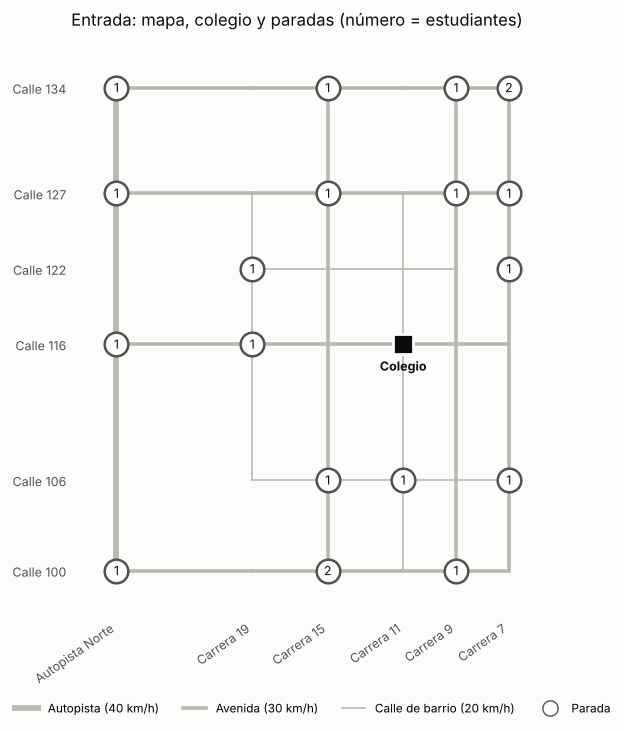

**Qué muestra:** el grafo que recibe el programa. Cada cruce de líneas es una esquina (vértice) y cada tramo es una calle (arista). El grosor indica la velocidad de la vía. El cuadro negro es el colegio y cada círculo es una parada con la cantidad de estudiantes que viven ahí.

**Relación con el proyecto:** es la entrada de la operación *Cargar el caso* y la estructura sobre la que trabajan Dijkstra y la validación con conjuntos disjuntos. Hay 36 esquinas, 54 tramos, 18 paradas y 20 estudiantes, porque en dos esquinas viven dos hermanos.


### Recurso 2. Traza de Dijkstra desde el colegio

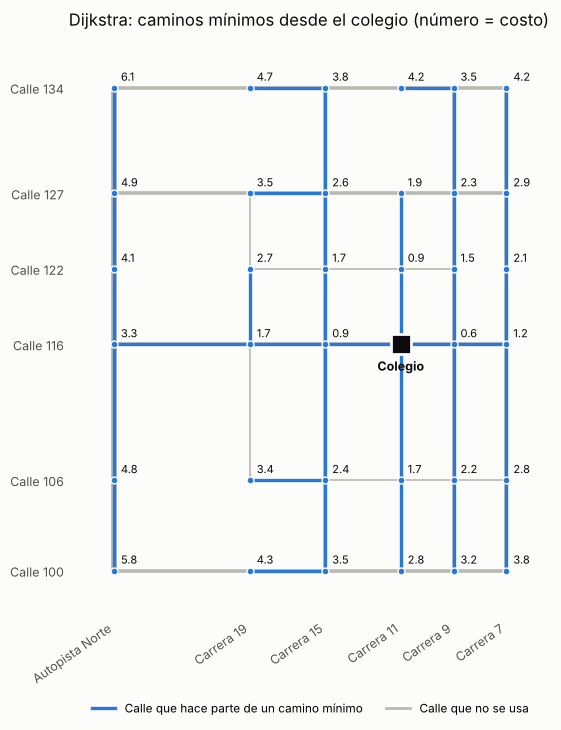

**Qué muestra:** las calles azules forman el árbol de caminos mínimos desde el colegio. El número de cada esquina es el costo ponderado del mejor camino hasta ella.

Estos son los primeros 8 pasos de la ejecución. En cada paso sale del montón mínimo la esquina pendiente de menor costo y queda cerrada:

| Paso | Esquina que sale del montón | Costo | Padre |
|---|---|---|---|
| 1 | Cl116-Kr11 (colegio) | 0 | - |
| 2 | Cl116-Kr9 | 0.61 | Cl116-Kr11 |
| 3 | Cl116-Kr15 | 0.87 | Cl116-Kr11 |
| 4 | Cl122-Kr11 | 0.95 | Cl116-Kr11 |
| 5 | Cl116-Kr7 | 1.21 | Cl116-Kr9 |
| 6 | Cl122-Kr9 | 1.47 | Cl116-Kr9 |
| 7 | Cl106-Kr11 | 1.70 | Cl116-Kr11 |
| 8 | Cl116-Kr19 | 1.73 | Cl116-Kr15 |

La ponderación cambia las decisiones. Estos dos tramos miden lo mismo, pero el de la autopista cuesta menos porque se recorre en la mitad del tiempo:

| Tramo | Km | Velocidad | Minutos | Costo ponderado |
|---|---|---|---|---|
| Carrera 11, de la Calle 116 a la Calle 122 | 0.5 | 20 km/h | 1.50 | 0.95 |
| Autopista Norte, de la Calle 116 a la Calle 122 | 0.5 | 40 km/h | 0.75 | 0.83 |

**Relación con el proyecto:** es el caso de uso de **caminos mínimos**. El programa ejecuta Dijkstra 19 veces (desde el colegio y desde las 18 paradas) y con esos costos decide el orden de las paradas y las calles por donde pasa cada bus.


### Recurso 3. Salida del MVP: rutas de la mañana y de la tarde

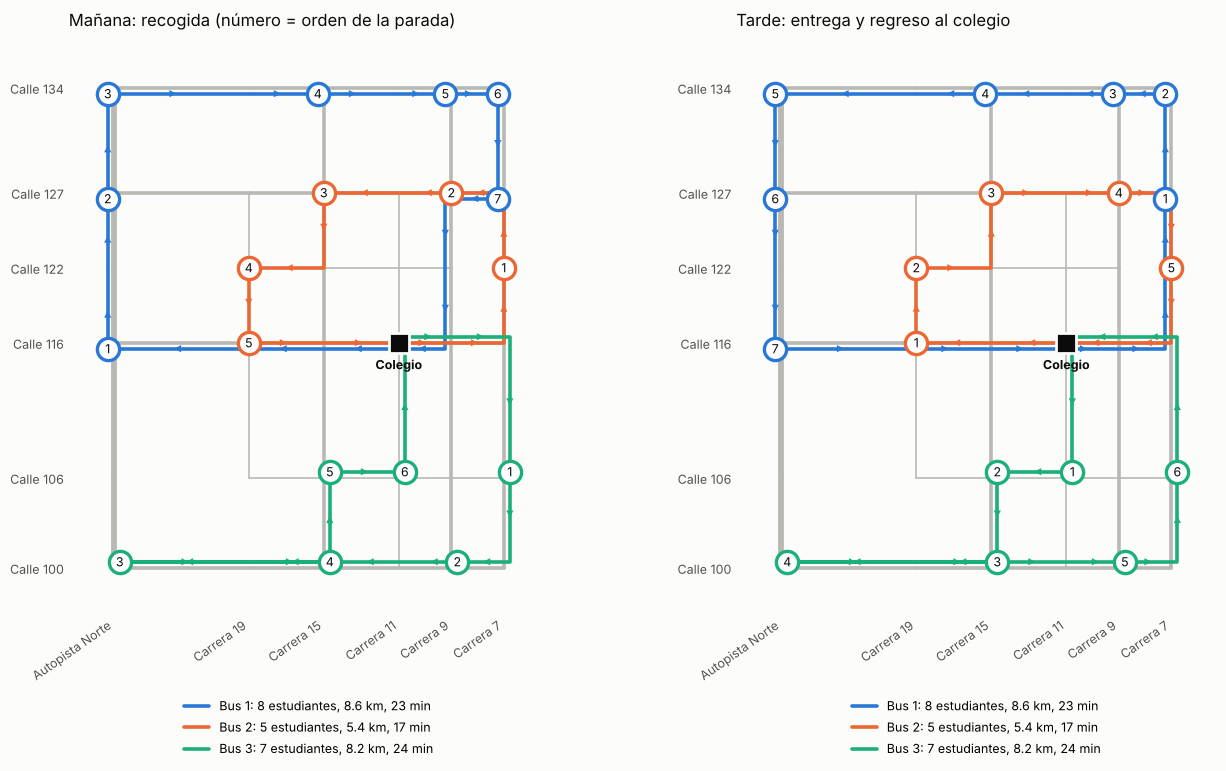

**Qué muestra:** el recorrido de cada bus sobre el mapa. Las flechas indican el sentido y el número de cada parada es el orden en que el bus pasa por ella. A la izquierda está la recogida de la mañana y a la derecha la entrega de la tarde.

**Relación con el proyecto:** es el resultado de la operación *Calcular las rutas*. El reparto entre buses sale de Clarke-Wright (montón máximo y conjuntos disjuntos), el orden de las paradas se mejora con 2-opt y el recorrido calle por calle se arma con la pila sobre los padres de Dijkstra. La ruta de la tarde es la de la mañana en sentido contrario. Para la mañana el programa elige el sentido en que los estudiantes pasan menos minutos en el bus, y ese recorrido al revés es también el que menos minutos les toma en la tarde.


### Recurso 4. Traza de Kruskal y árbol de expansión mínimo

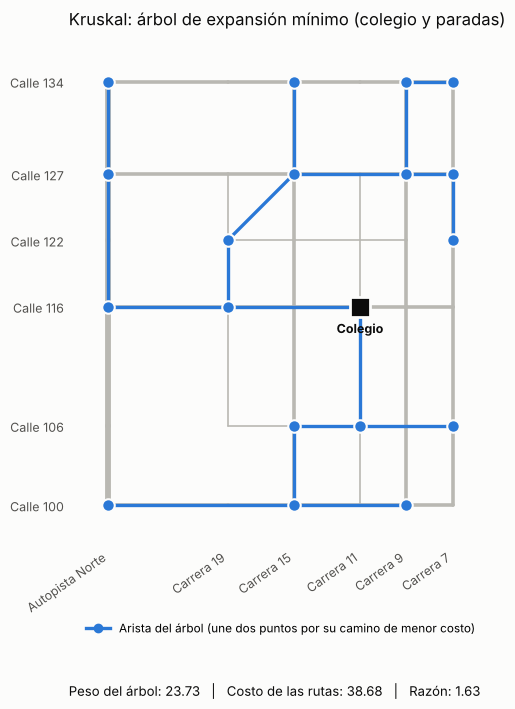

**Qué muestra:** el árbol de expansión mínimo que une el colegio con las 18 paradas. Cada arista une dos puntos y pesa el costo del camino mínimo entre ellos, por eso algunas se ven en diagonal.

Estos son los primeros 12 pasos. Las aristas salen del montón mínimo de menor a mayor y se aceptan solo si unen dos conjuntos distintos:

| Paso | Arista | Costo | Decisión |
|---|---|---|---|
| 1 | Cl127-Kr7 - Cl127-Kr9 | 0.61 | Se acepta |
| 2 | Cl134-Kr7 - Cl134-Kr9 | 0.61 | Se acepta |
| 3 | Cl127-Kr7 - Cl122-Kr7 | 0.87 | Se acepta |
| 4 | Cl106-Kr15 - Cl106-Kr11 | 0.95 | Se acepta |
| 5 | Cl122-Kr19 - Cl116-Kr19 | 0.95 | Se acepta |
| 6 | Cl100-Kr15 - Cl106-Kr15 | 1.04 | Se acepta |
| 7 | Cl134-Auto - Cl127-Auto | 1.16 | Se acepta |
| 8 | Cl127-Kr15 - Cl134-Kr15 | 1.21 | Se acepta |
| 9 | Cl127-Kr9 - Cl134-Kr9 | 1.21 | Se acepta |
| 10 | Cl134-Kr7 - Cl127-Kr7 | 1.21 | Se rechaza: ya estaban en el mismo conjunto (pasos 1, 2 y 9) y formaría un ciclo |
| 11 | Cl106-Kr7 - Cl106-Kr11 | 1.32 | Se acepta |
| 12 | Cl100-Kr15 - Cl100-Kr9 | 1.47 | Se acepta |

En total se revisaron 32 de las 171 aristas posibles: 18 aceptadas y 14 rechazadas.

**Relación con el proyecto:** es el caso de uso de **árboles de expansión mínimos**. Las rutas de los buses, juntas, conectan el colegio con todas las paradas, así que no pueden costar menos que este árbol. El árbol pesa 23.73 y las rutas cuestan 38.68, es decir, 1.63 veces la cota. Así el coordinador sabe qué tan lejos puede estar la ruta de la mejor posible, sin tener que conocerla.


### Recurso 5. Resultado para el negocio: ruta optimizada contra orden de inscripción

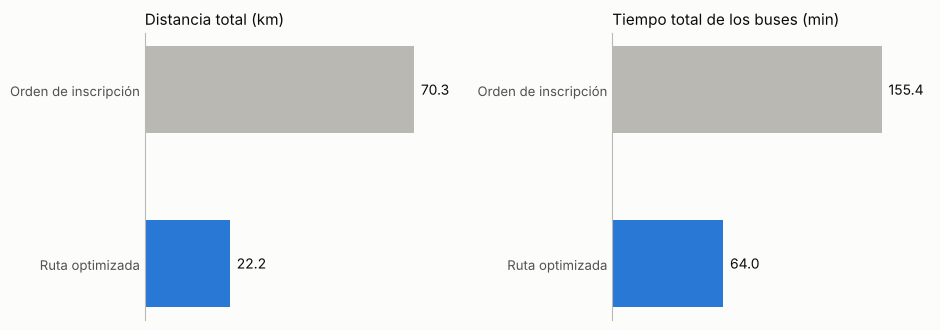

**Qué muestra:** la distancia y el tiempo totales de los tres buses si recogen a los estudiantes en el orden de inscripción, comparados con las rutas que calcula el programa.

**Relación con el proyecto:** es la salida de la operación *Comparar con la ruta sin optimizar* y responde al Problema 1 del caso de negocio. La distancia baja de 70.3 km a 22.2 km (68 %) y el tiempo de 155 min a 64 min (59 %).


## 7. Decisiones de estructuras de datos y algoritmos

No enumeres estructuras sin propósito. Explica una operación del caso y por qué la estructura o algoritmo la soporta. Incluye obligatoriamente una fila para **caminos mínimos** y otra para **árboles de expansión mínimos**.

En las complejidades, V son las esquinas (36), E los tramos de calle (54), k las paradas (18) y p los puntos del recorrido de un bus.

| Caso de uso u operación | Estructura o algoritmo | Datos que maneja | Invariante o condición | Complejidad esperada | Justificación |
|---|---|---|---|---|---|
| Caminos mínimos: saber por qué calles ir del colegio a cada parada, y de una parada a otra, con el menor costo ponderado | Dijkstra con cola de prioridad sobre montón mínimo | Grafo de calles con el costo ponderado en cada arista; pares (costo, esquina) en el montón | Los costos no son negativos. Cuando una esquina sale del montón por primera vez, su costo ya es el mínimo y no vuelve a cambiar | O((V + E) log V) por cada origen. Se ejecuta k + 1 veces | El bus solo puede andar por las calles, así que la distancia entre dos paradas es la del camino más corto y no la línea recta. Todos los costos son positivos, que es la condición de Dijkstra, y el montón entrega la esquina más cercana sin recorrer toda la lista |
| Árboles de expansión mínimos: medir qué tan buena es la ruta calculada | Kruskal con montón mínimo para sacar las aristas en orden y conjuntos disjuntos con Union-Find (unión por rango y compresión de caminos) para no formar ciclos | Grafo completo entre el colegio y las paradas; cada arista pesa el costo mínimo entre sus dos puntos | Una arista se acepta solo si sus extremos están en conjuntos distintos, así que nunca hay ciclos. Al final quedan k aristas y un solo conjunto | O(k² log k) para sacar las aristas del montón. Con Union-Find, cada findSet y cada union son O(α(k)) amortizado, así que el total lo domina el montón: O(k² log k) | Las rutas de todos los buses, juntas, conectan el colegio con todas las paradas, y por eso no pueden costar menos que el árbol de expansión mínimo. El programa usa ese peso como cota y dice cuántas veces la supera la ruta |
| Otra decisión pertinente: repartir los estudiantes entre los buses y ordenar las paradas | Ahorros de Clarke-Wright con montón máximo y conjuntos disjuntos con Union-Find; mejora con 2-opt | Ahorro de unir cada par de paradas; rutas en construcción | Cada parada está en una sola ruta. Dos rutas solo se unen por sus extremos y si juntas no pasan el cupo | O(k² log k) para los ahorros y O(α(k)) por cada findSet con Union-Find: O(k² log k) en total. 2-opt: O(k²) por pasada | Probar todos los repartos posibles crece de forma exponencial. Clarke-Wright siempre une primero lo que más ahorra, y para eso el montón máximo entrega el mayor ahorro en O(log k) |
| Otra decisión pertinente: consultar un estudiante por su id | Tabla hash con encadenamiento | Pares (id, datos del estudiante) | Cada id aparece una sola vez | O(1) en promedio | El padre busca por id y el tiempo de respuesta no debe depender de cuántos estudiantes hay |
| Otra decisión pertinente: comprobar que todos los estudiantes tienen camino al colegio | Conjuntos disjuntos con Union-Find | Esquinas y tramos de calle | Dos esquinas están en el mismo conjunto solo si hay camino entre ellas | O(E · α(V)) con Union-Find (unión por rango y compresión de caminos) | Detecta estudiantes aislados antes de calcular, por ejemplo después de cerrar una calle |
| Otra decisión pertinente: armar el recorrido calle por calle | Pila | Esquinas del camino, desde el destino hasta el origen | Lo último que entra es lo primero que sale | O(largo del camino) | Los padres de Dijkstra dan el camino al revés (del destino al origen) y la pila lo deja en el orden en que anda el bus |
| Otra decisión pertinente: simular por dónde va el bus a una hora | Cola | Puntos del recorrido con sus minutos acumulados | Los puntos salen en el mismo orden en que el bus pasa por ellos | p desencolados; cada pop(0) cuesta O(p) en una lista de Python | El recorrido se atiende en orden de llegada: el primer punto que entra es el primero por el que pasa el bus |


## 8. Contratos e invariantes

Para cada operación crítica, especifica precondiciones, poscondiciones y las propiedades que siempre deben conservarse.

| Operación | Precondiciones | Resultado esperado | Invariante que se conserva |
|---|---|---|---|
| `calcularRutas(caso)` | El caso pasa la validación: todos los estudiantes tienen camino al colegio, hay al menos un bus y los puestos alcanzan | Una ruta por bus que sale del colegio y vuelve a él, con los horarios de la mañana y de la tarde. Si no se puede, devuelve la lista de errores y ninguna ruta | Cada estudiante está en exactamente una ruta. Ningún bus lleva más estudiantes que puestos. El recorrido solo usa calles que existen en el grafo |
| `Graph.dijkstra(origen)` | El origen es una esquina del grafo y ningún costo es negativo | Costo mínimo y padre de cada esquina alcanzable; infinito para las que no tienen camino | Una esquina cerrada ya tiene su costo mínimo. El costo guardado de una esquina nunca aumenta |
| `kruskal(puntos, costo)` | Se conoce el costo mínimo entre cada par de puntos | Árbol con (puntos - 1) aristas que une todos los puntos con el menor peso total | Las aristas se revisan de menor a mayor. Las aceptadas nunca forman un ciclo |
| `ahorrosClarkeWright(...)` | Se conocen los costos entre el colegio y las paradas. Ninguna parada tiene más estudiantes que el cupo mayor | Grupos de paradas, cada uno en un orden de recorrido | Cada parada está en una sola ruta. La carga de cada ruta no pasa el cupo mayor |
| `consultarEstudiante(...)` | Las rutas ya están calculadas | Bus, estado, esquina por donde va el bus, km al colegio y minutos para llegar. Devuelve None si el id no existe | No modifica las rutas ni la tabla hash |
| `agregarEstudiante` y `retirarEstudiante` | Agregar: el id no existe y la esquina está en el mapa. Retirar: el id existe | La tabla hash y la lista de inscritos quedan actualizadas. Si no se cumple la precondición, devuelve el mensaje del problema y no cambia nada | No hay dos estudiantes con el mismo id |
| `cerrarCalle(caso, u, v)` | u y v son los extremos de un tramo | El tramo sale del grafo en los dos sentidos y devuelve True. Si no existía, devuelve False | El grafo sigue siendo no dirigido: si existe el tramo u-v, también existe v-u |
| `DisjointSets.findSet` y `DisjointSets.union` | findSet: el elemento pertenece a algún conjunto. union: los dos elementos existen | findSet devuelve la raíz del conjunto; union devuelve False si ya estaban en el mismo conjunto | La raíz de un conjunto solo cambia cuando union la cuelga de otra; el rango de una raíz nunca disminuye |
| `Heap.insert` y `Heap.extract` | Extract: el montón no está vacío | Insert agrega el elemento. Extract saca el menor (montón mínimo) o el mayor (montón máximo) | Propiedad de montón: ningún hijo va antes que su padre |


## 9. Implementación prevista

Describe qué función, clase o módulo implementará cada operación crítica. Agrega pseudocódigo cuando ayude a comunicar una decisión antes de programarla.

**Instrucciones de ejecución:** en Colab, *Entorno de ejecución > Ejecutar todas*. El cuaderno no necesita archivos ni instalar nada. Las celdas de código están en este orden: estructuras, datos del caso, solución, gráficas, demo, figuras y, en la sección 10, pruebas.

| Operación | Función o clase que la implementa |
|---|---|
| Cargar el caso | `construirMapa`, `construirCaso` |
| Validar los datos | `validarDatos` con `DisjointSets` |
| Caminos mínimos | `Graph.dijkstra` con `PriorityQueue` y `Heap`; `calcularCostos`; `caminoCalles` (pila) |
| Repartir estudiantes y ordenar paradas | `ahorrosClarkeWright`, `mejorar2opt`, `asignarBuses` |
| Árbol de expansión mínimo | `kruskal` |
| Rutas de la mañana y de la tarde | `calcularRutas`, `minutosABordo`, `construirHorario` |
| Vista de padres | `consultarEstudiante` con `HashTable` y una cola |
| Cambios | `agregarEstudiante`, `retirarEstudiante`, `cerrarCalle` |
| Comparación | `rutaSinOptimizar` |
| Gráficas | `graficarEntrada`, `graficarCaminosMinimos`, `graficarRutas`, `graficarArbolMinimo`, `graficarComparacion` |
| Demo y pruebas | `ejecutar_demo`, `ejecutar_pruebas` y la lista `casos_de_prueba` |

**Pseudocódigo de la operación principal:**

```
calcularRutas(caso):
    si validarDatos(caso) encuentra problemas: devolver los problemas
    paradas = agrupar a los estudiantes por esquina
    costo, padres = Dijkstra desde el colegio y desde cada parada
    para cada peso de ahorro:
        rutas = Clarke-Wright(paradas, costo, cupo mayor, peso)
        mejorar cada ruta con 2-opt
        asignar la ruta con más estudiantes al bus con más puestos
        quedarse con el reparto válido de menor costo
    para cada bus:
        elegir el sentido en que los estudiantes pasan menos minutos en el bus
        armar el horario de la mañana y el de la tarde (orden inverso)
    árbol = Kruskal(colegio y paradas, costo)
    guardar en la tabla hash el bus y la parada de cada estudiante
```

**Cambios al código base de clase:**

- `Heap`: se completó `min_heapify`; `insert` ahora sube el elemento nuevo en O(log n) en vez de reconstruir todo el montón; se agregó `extract`, que saca la raíz en O(log n), y `PriorityQueue.dequeue` lo usa.
- `HashTable`: se corrigieron `update` y `delete`, que fallaban porque los pares (clave, valor) son tuplas; se quitó el print de `insert`.
- `Graph`: cada arista lleva un peso; se agregaron `dijkstra` y `removeEdge`.
- `DisjointSets`: se usa igual que en clase.

**Interfaz:** el MVP también tiene una ventana de escritorio (carpeta `efiruta_escritorio`, se abre con `python app.py`). Ahí se ve el recorrido de los buses en movimiento, las decisiones paso a paso y la vista de padres, y el coordinador puede agregar estudiantes, cerrar calles y cambiar los buses. Usa estas mismas funciones. En el cuaderno el recorrido se muestra con gráficas porque Colab no puede abrir ventanas.


In [1]:
# ===================== ESTRUCTURAS DE DATOS (código base de clase, adaptado) =====================
import math

WHITE = "white"
BLACK = "black"
GRAY = "gray"


class Heap:
    # config : True // Max_Heap
    # config : False // Min_heap
    def __init__(self, data=[], config=True):
        self.data = []
        self.config = config
        self.build(data[:])

    def left(self, index):
        return 2 * index + 1

    def right(self, index):
        return 2 * (index + 1)

    def parent(self, index):
        return (index - 1) // 2

    def __len__(self):
        return len(self.data)

    def goesAbove(self, child, parent):
        # Dice si el hijo debe quedar por encima del padre según el tipo de montón
        if self.config:
            return self.data[parent] < self.data[child]
        return self.data[child] < self.data[parent]

    def insert(self, new):
        # Corregido: el elemento nuevo entra al final y sube hasta su lugar. O(log n)
        self.data.append(new)
        index = len(self.data) - 1
        while index > 0 and self.goesAbove(index, self.parent(index)):
            parent_index = self.parent(index)
            self.data[parent_index], self.data[index] = self.data[index], self.data[parent_index]
            index = parent_index

    def extract(self):
        # Corregido: saca la raíz pasando el último elemento arriba y bajándolo. O(log n)
        if len(self) == 0:
            raise Exception("El montón está vacio")
        top = self.data[0]
        last = self.data.pop()
        if len(self) > 0:
            self.data[0] = last
            self.heapify(0)
        return top

    def build(self, data=[]):
        if data and len(data) > 0 and isinstance(data, list):
            self.data = data
        for index in range(len(self) // 2, -1, -1):
            self.heapify(index)

    def heapify(self, index):
        if self.config:
            self.max_heapify(index)
        else:
            self.min_heapify(index)

    def max_heapify(self, index):
        left_index, right_index, largest_index = self.left(index), self.right(index), index
        if left_index < len(self) and self.data[largest_index] < self.data[left_index]:
            largest_index = left_index
        if right_index < len(self) and self.data[largest_index] < self.data[right_index]:
            largest_index = right_index
        if largest_index != index:
            self.data[largest_index], self.data[index] = self.data[index], self.data[largest_index]
            self.max_heapify(largest_index)

    def min_heapify(self, index):
        # Completado: igual que max_heapify, pero deja arriba al menor
        left_index, right_index, smallest_index = self.left(index), self.right(index), index
        if left_index < len(self) and self.data[left_index] < self.data[smallest_index]:
            smallest_index = left_index
        if right_index < len(self) and self.data[right_index] < self.data[smallest_index]:
            smallest_index = right_index
        if smallest_index != index:
            self.data[smallest_index], self.data[index] = self.data[index], self.data[smallest_index]
            self.min_heapify(smallest_index)

    def peek(self):
        return self.data[0]


class PriorityQueue:
    def __init__(self, data=[], config=True):
        self.data = Heap(data, config)

    def __len__(self):
        return len(self.data)

    def enqueue(self, new):
        self.data.insert(new)

    def dequeue(self):
        if len(self) == 0:
            raise Exception("Underflow")
        return self.data.extract()


class HashTable:
    def __init__(self, size):
        self.elements = [ [] for x in range(size)]

    def hash(self, key):
        return hash(key) % len(self.elements)

    def insert(self, key, value):
        # Se quitó el print de cada inserción para no llenar la salida
        index = self.hash(key)
        self.elements[index].append((key, value))

    def search(self, key):
        index = self.hash(key)
        for e in self.elements[index]:
            if e[0] == key:
                return e[1]
        return None

    def update(self, key, value2):
        # Corregido: se reemplaza la tupla completa (las tuplas no se pueden modificar)
        index = self.hash(key)
        for pos in range(len(self.elements[index])):
            if self.elements[index][pos][0] == key:
                self.elements[index][pos] = (key, value2)

    def delete(self, key):
        # Corregido: se elimina el par (clave, valor) completo
        index = self.hash(key)
        for e in self.elements[index]:
            if e[0] == key:
                self.elements[index].remove(e)
                return


class DisjointSets:
    # Conjuntos disjuntos con Union-Find. Cada elemento guarda su padre y su rango.
    # La unión por rango cuelga el árbol más bajo del más alto y la compresión de caminos
    # aplana el árbol en cada findSet, así que las dos operaciones son O(alfa(n)) amortizado
    def __init__(self, A):
        self.padre = {}
        self.rango = {}
        for x in A:
            self.padre[x] = x
            self.rango[x] = 0

    def findSet(self, x):
        # Devuelve la raíz del conjunto de x, comprimiendo el camino a la raíz
        if x not in self.padre:
            return None
        raiz = x
        while self.padre[raiz] != raiz:
            raiz = self.padre[raiz]
        while self.padre[x] != raiz:
            siguiente = self.padre[x]
            self.padre[x] = raiz
            x = siguiente
        return raiz

    def makeSet(self, x):
        if x not in self.padre:
            self.padre[x] = x
            self.rango[x] = 0
        return self.findSet(x)

    def cuentaConjuntos(self):
        # Cuenta cuántas raíces distintas quedan: una por cada conjunto o zona conectada
        raices = set()
        for x in self.padre:
            raices.add(self.findSet(x))
        return len(raices)

    def union(self, x, y):
        # Une los conjuntos de x y de y por rango. Devuelve False si ya estaban juntos
        raizX = self.findSet(x)
        raizY = self.findSet(y)
        if raizX is None:
            raizX = self.makeSet(x)
        if raizY is None:
            raizY = self.makeSet(y)
        if raizX == raizY:
            return False
        if self.rango[raizX] < self.rango[raizY]:
            raizX, raizY = raizY, raizX
        self.padre[raizY] = raizX
        if self.rango[raizX] == self.rango[raizY]:
            self.rango[raizX] = self.rango[raizX] + 1
        return True


class Graph:
    # Cada relación es (u, v, peso). En este proyecto el peso es el costo ponderado de la calle
    def _buildRelation(self, e):
        if self.directed:
            self.relations = e
        else:
            self.relations = set()
            for el in e:
                self.relations.add(el)
                self.relations.add((el[1], el[0], el[2]))

    def _buildAdjList(self):
        self.adjList = {}
        for v in self.vertexes:
            self.adjList[v] = []
        for relation in self.relations:
            self.adjList[relation[0]].append(relation[1])

    def _buildWeights(self):
        self.weights = {}
        for relation in self.relations:
            self.weights[(relation[0], relation[1])] = relation[2]

    def __init__(self, v, e, directed = True):
        self.directed = directed
        self.vertexes = v
        self._buildRelation(e)
        self._buildAdjList()
        self._buildWeights()

    def getNeighbors(self, vertex):
        return self.adjList[vertex]

    def removeEdge(self, u, v):
        # Quita la calle u-v (y v-u si no es dirigido) y reconstruye la lista de adyacencia
        newRelations = set()
        found = False
        for relation in self.relations:
            if relation[0] == u and relation[1] == v:
                found = True
            elif relation[0] == v and relation[1] == u and not self.directed:
                found = True
            else:
                newRelations.add(relation)
        self.relations = newRelations
        self._buildAdjList()
        self._buildWeights()
        return found

    def _buildVProps(self, source = None):
        self.v_props = {}
        for v in self.vertexes:
            self.v_props[v] = {'color': WHITE, 'distance': math.inf, 'parent': None}
        if source is not None:
            self.v_props[source] = {'color': GRAY, 'distance': 0, 'parent': None}

    def dijkstra(self, source):
        # Caminos mínimos desde source con cola de prioridad (montón mínimo).
        # En la cola van pares (costo, vértice). Un vértice se cierra (BLACK) la primera vez que sale,
        # y en ese momento su costo ya es el mínimo. self.order guarda el orden en que se cierran
        self._buildVProps(source)
        self.order = []
        pq = PriorityQueue([], False)
        pq.enqueue((0, source))
        while len(pq) > 0:
            d, u = pq.dequeue()
            if self.v_props[u]['color'] != BLACK:
                self.v_props[u]['color'] = BLACK
                self.order.append(u)
                for neighbor in self.getNeighbors(u):
                    newDistance = d + self.weights[(u, neighbor)]
                    if newDistance < self.v_props[neighbor]['distance']:
                        self.v_props[neighbor]['distance'] = newDistance
                        self.v_props[neighbor]['parent'] = u
                        pq.enqueue((newDistance, neighbor))
        return self.v_props


In [2]:
# ===================== DATOS DEL CASO: zona norte de Bogotá =====================
# Mapa simplificado: los nombres de las vías son reales; las distancias (km) y las
# velocidades (km/h) son aproximadas y se usan solo para la simulación.

# (código, nombre, posición en km, velocidad en km/h)
CARRERAS = [('Auto', 'Autopista Norte', 0.0, 40), ('Kr19', 'Carrera 19', 0.9, 20),
            ('Kr15', 'Carrera 15', 1.4, 30), ('Kr11', 'Carrera 11', 1.9, 20),
            ('Kr9', 'Carrera 9', 2.25, 30), ('Kr7', 'Carrera 7', 2.6, 30)]
CALLES = [('Cl100', 'Calle 100', 0.0, 30), ('Cl106', 'Calle 106', 0.6, 20),
          ('Cl116', 'Calle 116', 1.5, 30), ('Cl122', 'Calle 122', 2.0, 20),
          ('Cl127', 'Calle 127', 2.5, 30), ('Cl134', 'Calle 134', 3.2, 30)]

# Tramos que no existen en el mapa (no hay paso entre esas dos esquinas)
SIN_PASO = [('Cl106-Kr19', 'Cl106-Auto'), ('Cl122-Kr19', 'Cl122-Auto'), ('Cl122-Kr9', 'Cl122-Kr7'),
            ('Cl127-Kr11', 'Cl134-Kr11'), ('Cl100-Kr19', 'Cl106-Kr19'), ('Cl127-Kr19', 'Cl134-Kr19')]

COLEGIO = 'Cl116-Kr11'

# (id, nombre, esquina donde vive)
ESTUDIANTES = [('1001', 'Ana', 'Cl134-Kr7'), ('1002', 'Luis', 'Cl100-Auto'), ('1003', 'Sofia', 'Cl127-Kr15'),
               ('1004', 'Mateo', 'Cl106-Kr7'), ('1005', 'Valentina', 'Cl134-Kr15'), ('1006', 'Samuel', 'Cl134-Kr7'),
               ('1007', 'Isabella', 'Cl100-Kr15'), ('1008', 'Martin', 'Cl122-Kr19'), ('1009', 'Camila', 'Cl127-Kr7'),
               ('1010', 'Tomas', 'Cl116-Auto'), ('1011', 'Lucia', 'Cl100-Kr9'), ('1012', 'Andres', 'Cl134-Auto'),
               ('1013', 'Mariana', 'Cl106-Kr15'), ('1014', 'Juan', 'Cl127-Kr9'), ('1015', 'Daniela', 'Cl100-Kr15'),
               ('1016', 'Felipe', 'Cl122-Kr7'), ('1017', 'Sara', 'Cl127-Auto'), ('1018', 'Nicolas', 'Cl106-Kr11'),
               ('1019', 'Gabriela', 'Cl134-Kr9'), ('1020', 'David', 'Cl116-Kr19')]

# Puestos de cada bus (la cantidad de buses es la cantidad de números)
BUSES = [8, 7, 7]

PESO_DISTANCIA = 0.8
PESO_TIEMPO = 0.2
MINUTOS_POR_PARADA = 1          # tiempo que el bus se detiene en cada parada
SALIDA_MANANA = 6 * 60          # 6:00 a. m. en minutos desde la medianoche
SALIDA_TARDE = 15 * 60          # 3:00 p. m.
TAMANO_TABLA = 101
PESOS_AHORRO = [1.0, 0.6, 0.8, 1.2, 1.4, 1.6, 1.8, 2.0]


def construirMapa():
    # Arma las esquinas y los tramos de calle a partir de las listas de calles y carreras.
    # Devuelve: nodos, coords (esquina -> (x, y)) y tramos (u, v, km, velocidad)
    nodos = []
    coords = {}
    for calle in CALLES:
        for carrera in CARRERAS:
            nodo = calle[0] + '-' + carrera[0]
            nodos.append(nodo)
            coords[nodo] = (carrera[2], calle[2])
    tramos = []
    for calle in CALLES:                       # tramos sobre cada calle (oriente-occidente)
        for c in range(len(CARRERAS) - 1):
            u = calle[0] + '-' + CARRERAS[c][0]
            v = calle[0] + '-' + CARRERAS[c + 1][0]
            km = round(CARRERAS[c + 1][2] - CARRERAS[c][2], 2)
            if (u, v) not in SIN_PASO and (v, u) not in SIN_PASO:
                tramos.append((u, v, km, calle[3]))
    for carrera in CARRERAS:                   # tramos sobre cada carrera (sur-norte)
        for c in range(len(CALLES) - 1):
            u = CALLES[c][0] + '-' + carrera[0]
            v = CALLES[c + 1][0] + '-' + carrera[0]
            km = round(CALLES[c + 1][2] - CALLES[c][2], 2)
            if (u, v) not in SIN_PASO and (v, u) not in SIN_PASO:
                tramos.append((u, v, km, carrera[3]))
    return nodos, coords, tramos


In [3]:
# ===================== SOLUCIÓN DEL PROBLEMA =====================

def construirCaso(nodos, coords, tramos, colegio, estudiantes, capacidades):
    # Escribe los datos en las estructuras: grafo (calles), diccionarios (km y minutos) y tabla hash (estudiantes).
    # Ponderación: costo = 0.8 * (km / km promedio) + 0.2 * (minutos / minutos promedio)
    km = {}
    minutos = {}
    sumaKm = 0
    sumaMin = 0
    for tramo in tramos:
        if tramo[0] not in nodos or tramo[1] not in nodos:
            raise Exception('La calle ' + str(tramo[0]) + ' - ' + str(tramo[1]) + ' usa una esquina que no existe')
        tiempo = tramo[2] / tramo[3] * 60
        km[(tramo[0], tramo[1])] = tramo[2]
        km[(tramo[1], tramo[0])] = tramo[2]
        minutos[(tramo[0], tramo[1])] = tiempo
        minutos[(tramo[1], tramo[0])] = tiempo
        sumaKm = sumaKm + tramo[2]
        sumaMin = sumaMin + tiempo
    kmProm = sumaKm / len(tramos)
    minProm = sumaMin / len(tramos)
    relaciones = []
    for tramo in tramos:
        costo = PESO_DISTANCIA * tramo[2] / kmProm + PESO_TIEMPO * minutos[(tramo[0], tramo[1])] / minProm
        relaciones.append((tramo[0], tramo[1], costo))
    tabla = HashTable(TAMANO_TABLA)
    ids = []
    for est in estudiantes:
        if tabla.search(est[0]) is None:
            tabla.insert(est[0], {'nombre': est[1], 'nodo': est[2], 'bus': None, 'orden': None})
            ids.append(est[0])
    return {'grafo': Graph(nodos, relaciones, False), 'coords': coords, 'km': km, 'minutos': minutos,
            'kmProm': kmProm, 'minProm': minProm, 'colegio': colegio, 'tabla': tabla, 'ids': ids,
            'capacidades': list(capacidades)}


def validarDatos(caso):
    # Conjuntos disjuntos: se une cada calle y queda un conjunto por cada zona conectada.
    # Un estudiante es alcanzable si su esquina está en el mismo conjunto que el colegio
    grafo, colegio, tabla = caso['grafo'], caso['colegio'], caso['tabla']
    errores = []
    if colegio not in grafo.vertexes:
        errores.append('El colegio (' + str(colegio) + ') no es una esquina del mapa')
        return errores
    dj = DisjointSets(grafo.vertexes)
    for relation in grafo.relations:
        dj.union(relation[0], relation[1])
    conjuntoColegio = dj.findSet(colegio)
    for idEst in caso['ids']:
        est = tabla.search(idEst)
        if est['nodo'] not in grafo.vertexes:
            errores.append('El estudiante ' + idEst + ' (' + est['nombre'] + ') vive en ' + est['nodo'] + ', que no existe en el mapa')
        elif dj.findSet(est['nodo']) != conjuntoColegio:
            errores.append('El estudiante ' + idEst + ' (' + est['nombre'] + ') vive en ' + est['nodo'] + ', que no tiene camino al colegio')
    if len(caso['capacidades']) == 0:
        errores.append('No hay buses')
    for cupo in caso['capacidades']:
        if cupo <= 0:
            errores.append('Hay un bus con ' + str(cupo) + ' puestos')
    if len(caso['ids']) > sum(caso['capacidades']):
        errores.append('Hay ' + str(len(caso['ids'])) + ' estudiantes y solo ' + str(sum(caso['capacidades'])) + ' puestos en total')
    return errores


def agruparParadas(caso):
    # Los estudiantes que viven en la misma esquina (por ejemplo hermanos) comparten parada
    paradas = {}
    nodos = []
    for idEst in caso['ids']:
        nodo = caso['tabla'].search(idEst)['nodo']
        if nodo not in paradas:
            paradas[nodo] = []
            nodos.append(nodo)
        paradas[nodo].append(idEst)
    return paradas, nodos


def calcularCostos(grafo, origenes):
    # Un Dijkstra por cada origen. costo[(a, b)] = costo mínimo de a a b; padres[a] = árbol de caminos desde a
    costo = {}
    padres = {}
    for origen in origenes:
        props = grafo.dijkstra(origen)
        padres[origen] = {}
        for v in grafo.vertexes:
            costo[(origen, v)] = props[v]['distance']
            padres[origen][v] = props[v]['parent']
    return costo, padres


def caminoCalles(padres, origen, destino):
    # Pila: se sube desde el destino por los padres de Dijkstra y al sacar queda en orden origen -> destino
    pila = []
    actual = destino
    while actual is not None:
        pila.append(actual)
        actual = padres[origen][actual]
    camino = []
    while len(pila) > 0:
        camino.append(pila.pop())
    return camino


def medirCamino(camino, km, minutos):
    totalKm = 0
    totalMin = 0
    for p in range(len(camino) - 1):
        totalKm = totalKm + km[(camino[p], camino[p + 1])]
        totalMin = totalMin + minutos[(camino[p], camino[p + 1])]
    return totalKm, totalMin


def cargaRuta(ruta, paradas):
    carga = 0
    for nodo in ruta:
        carga = carga + len(paradas[nodo])
    return carga


def costoRuta(orden, colegio, costo):
    if len(orden) == 0:
        return 0
    puntos = [colegio] + orden + [colegio]
    total = 0
    for p in range(len(puntos) - 1):
        total = total + costo[(puntos[p], puntos[p + 1])]
    return total


def ahorrosClarkeWright(colegio, nodos, paradas, costo, capMax, peso, registro):
    # Al inicio cada parada es su propia ruta: colegio -> parada -> colegio.
    # Unir las rutas de i y j ahorra: c(colegio, i) + c(colegio, j) - peso * c(i, j)
    # Los ahorros salen de un montón máximo (primero el mayor) y los conjuntos disjuntos
    # dicen si i y j ya están en la misma ruta
    dj = DisjointSets(nodos)
    rutaDe = {}
    for nodo in nodos:
        rutaDe[nodo] = [nodo]
    ahorros = PriorityQueue([], True)
    for a in range(len(nodos)):
        for b in range(a + 1, len(nodos)):
            i, j = nodos[a], nodos[b]
            ahorro = costo[(colegio, i)] + costo[(colegio, j)] - peso * costo[(i, j)]
            ahorros.enqueue((ahorro, i, j))
    descartadas = 0
    while len(ahorros) > 0:
        ahorro, i, j = ahorros.dequeue()
        if dj.findSet(i) != dj.findSet(j):
            rutaI, rutaJ = rutaDe[i], rutaDe[j]
            # Solo se pueden pegar dos rutas por sus extremos
            extremoI = rutaI[0] == i or rutaI[len(rutaI) - 1] == i
            extremoJ = rutaJ[0] == j or rutaJ[len(rutaJ) - 1] == j
            carga = cargaRuta(rutaI, paradas) + cargaRuta(rutaJ, paradas)
            if extremoI and extremoJ and carga <= capMax:
                # Se voltean para que quede ... i -> j ...
                if rutaI[0] == i:
                    rutaI.reverse()
                if rutaJ[len(rutaJ) - 1] == j:
                    rutaJ.reverse()
                nueva = rutaI + rutaJ
                for nodo in nueva:
                    rutaDe[nodo] = nueva
                dj.union(i, j)
                registro.append('Clarke-Wright: se unen las rutas por ' + i + ' y ' + j + ' (ahorro ' + str(round(ahorro, 2)) + ', quedan ' + str(carga) + ' estudiantes)')
            elif extremoI and extremoJ:
                descartadas = descartadas + 1
    registro.append('Clarke-Wright: ' + str(descartadas) + ' uniones descartadas porque el bus pasaría de ' + str(capMax) + ' puestos')
    # Cada ruta se toma una sola vez: desde su primera parada
    rutas = []
    for nodo in nodos:
        if rutaDe[nodo][0] == nodo:
            rutas.append(rutaDe[nodo])
    return rutas


def mejorar2opt(orden, colegio, costo, registro):
    # 2-opt: si invertir un tramo de la ruta la hace más barata, se invierte.
    # Se repite hasta que ninguna inversión mejore
    ruta = [colegio] + orden + [colegio]
    mejoro = True
    while mejoro:
        mejoro = False
        for a in range(1, len(ruta) - 2):
            for b in range(a + 1, len(ruta) - 1):
                antes = costo[(ruta[a - 1], ruta[a])] + costo[(ruta[b], ruta[b + 1])]
                despues = costo[(ruta[a - 1], ruta[b])] + costo[(ruta[a], ruta[b + 1])]
                if despues < antes - 0.000001:
                    registro.append('2-opt: se invierte el tramo ' + ruta[a] + ' ... ' + ruta[b] + ' (ahorra ' + str(round(antes - despues, 2)) + ')')
                    tramo = ruta[a:b + 1]
                    tramo.reverse()
                    ruta = ruta[:a] + tramo + ruta[b + 1:]
                    mejoro = True
    return ruta[1:len(ruta) - 1]


def asignarBuses(rutas, paradas, capacidades):
    # La ruta con más estudiantes va al bus con más puestos, y así sucesivamente (dos montones máximos)
    if len(rutas) > len(capacidades):
        return None
    pqRutas = PriorityQueue([], True)
    for r in range(len(rutas)):
        pqRutas.enqueue((cargaRuta(rutas[r], paradas), r))
    pqBuses = PriorityQueue([], True)
    for b in range(len(capacidades)):
        pqBuses.enqueue((capacidades[b], b))
    asignacion = [[] for b in range(len(capacidades))]
    while len(pqRutas) > 0:
        carga, r = pqRutas.dequeue()
        cupo, b = pqBuses.dequeue()
        if carga > cupo:
            return None
        asignacion[b] = rutas[r]
    return asignacion


def kruskal(puntos, costo):
    # Árbol de expansión mínimo sobre el colegio y las paradas (la arista a-b pesa el costo mínimo entre a y b).
    # Las aristas salen de menor a mayor de un montón mínimo; se acepta la que une dos conjuntos distintos
    pq = PriorityQueue([], False)
    for a in range(len(puntos)):
        for b in range(a + 1, len(puntos)):
            pq.enqueue((costo[(puntos[a], puntos[b])], puntos[a], puntos[b]))
    dj = DisjointSets(puntos)
    aristas = []
    traza = []
    peso = 0
    while len(pq) > 0 and len(aristas) < len(puntos) - 1:
        c, a, b = pq.dequeue()
        if dj.findSet(a) != dj.findSet(b):
            dj.union(a, b)
            aristas.append((a, b, c))
            peso = peso + c
            traza.append((a, b, c, True))
        else:
            traza.append((a, b, c, False))
    return aristas, peso, traza


def minutosABordo(orden, colegio, paradas, minEntre):
    # Suma de los minutos que cada estudiante pasa en el bus en la mañana (desde que sube hasta el colegio)
    total = 0
    alColegio = 0
    siguiente = colegio
    for i in range(len(orden) - 1, -1, -1):
        alColegio = alColegio + minEntre[(orden[i], siguiente)]
        total = total + alColegio * len(paradas[orden[i]])
        alColegio = alColegio + MINUTOS_POR_PARADA
        siguiente = orden[i]
    return total


def construirHorario(orden, colegio, padres, km, minutos, paradas):
    # Lista de puntos por donde pasa el bus, con km y minutos acumulados desde la salida.
    # En las paradas se guarda quiénes suben (mañana) o bajan (tarde)
    horario = [{'nodo': colegio, 'km': 0, 'min': 0, 'estudiantes': []}]
    if len(orden) == 0:
        return horario
    puntos = [colegio] + orden + [colegio]
    kmAcum = 0
    minAcum = 0
    for p in range(len(puntos) - 1):
        tramo = caminoCalles(padres, puntos[p], puntos[p + 1])
        for k in range(1, len(tramo)):
            kmAcum = kmAcum + km[(tramo[k - 1], tramo[k])]
            minAcum = minAcum + minutos[(tramo[k - 1], tramo[k])]
            horario.append({'nodo': tramo[k], 'km': kmAcum, 'min': minAcum, 'estudiantes': []})
        if len(tramo) == 1:
            horario.append({'nodo': puntos[p + 1], 'km': kmAcum, 'min': minAcum, 'estudiantes': []})
        if p + 1 < len(puntos) - 1:
            horario[len(horario) - 1]['estudiantes'] = paradas[puntos[p + 1]]
            minAcum = minAcum + MINUTOS_POR_PARADA
    return horario


def calcularRutas(caso):
    grafo, colegio, tabla, ids, capacidades = caso['grafo'], caso['colegio'], caso['tabla'], caso['ids'], caso['capacidades']
    plan = {'errores': validarDatos(caso)}
    if len(ids) == 0:
        plan['errores'].append('No hay estudiantes inscritos')
    if len(plan['errores']) > 0:
        return plan
    paradas, nodos = agruparParadas(caso)
    capMax = max(capacidades)
    for nodo in nodos:
        if len(paradas[nodo]) > capMax:
            plan['errores'].append('En la parada ' + nodo + ' hay ' + str(len(paradas[nodo])) + ' estudiantes y ningún bus tiene tantos puestos')
    if len(plan['errores']) > 0:
        return plan
    decisiones = []

    # 1. Caminos mínimos (Dijkstra) desde el colegio y desde cada parada
    puntos = [colegio]
    for nodo in nodos:
        if nodo != colegio:
            puntos.append(nodo)
    costo, padres = calcularCostos(grafo, puntos)
    kmEntre = {}
    minEntre = {}
    for a in puntos:
        for b in puntos:
            kmEntre[(a, b)], minEntre[(a, b)] = medirCamino(caminoCalles(padres, a, b), caso['km'], caso['minutos'])
    decisiones.append('Dijkstra: caminos de menor costo desde el colegio y desde las ' + str(len(puntos) - 1) + ' paradas (' + str(len(puntos)) + ' ejecuciones)')

    # 2. Reparto y orden: Clarke-Wright con varios pesos + 2-opt; se queda la asignación válida más barata
    asignacion = None
    mejorTotal = None
    mejorRegistro = None
    mejorPeso = None
    for peso in PESOS_AHORRO:
        registro = []
        rutas = ahorrosClarkeWright(colegio, nodos, paradas, costo, capMax, peso, registro)
        for r in range(len(rutas)):
            rutas[r] = mejorar2opt(rutas[r], colegio, costo, registro)
        candidata = asignarBuses(rutas, paradas, capacidades)
        if candidata is not None:
            totalCandidata = 0
            for ruta in candidata:
                totalCandidata = totalCandidata + costoRuta(ruta, colegio, costo)
            if mejorTotal is None or totalCandidata < mejorTotal - 0.000001:
                asignacion, mejorTotal, mejorRegistro, mejorPeso = candidata, totalCandidata, registro, peso
    if asignacion is None:
        plan['errores'].append('Con ' + str(len(capacidades)) + ' buses y esos puestos no se logró repartir a los estudiantes. Pruebe con más buses o más puestos')
        return plan
    decisiones.append('Se probaron ' + str(len(PESOS_AHORRO)) + ' pesos de ahorro; el mejor fue ' + str(mejorPeso) + ' con costo total ' + str(round(mejorTotal, 2)))
    for linea in mejorRegistro:
        decisiones.append(linea)

    # 3. Sentido del recorrido y horarios de la mañana y de la tarde
    buses = []
    totalKm = 0
    totalMin = 0
    for b in range(len(capacidades)):
        orden = asignacion[b]
        if len(orden) > 0:
            alReves = orden[:]
            alReves.reverse()
            ida = minutosABordo(orden, colegio, paradas, minEntre)
            vuelta = minutosABordo(alReves, colegio, paradas, minEntre)
            if vuelta < ida - 0.000001:
                orden = alReves
            decisiones.append('Bus ' + str(b + 1) + ': ' + str(cargaRuta(orden, paradas)) + ' estudiantes (cupo ' + str(capacidades[b]) + '). Sentido elegido: empieza en ' + orden[0] + ' (' + str(round(min(ida, vuelta), 1)) + ' minutos de estudiantes a bordo contra ' + str(round(max(ida, vuelta), 1)) + ' en el otro sentido)')
        tarde = orden[:]
        tarde.reverse()
        horarioManana = construirHorario(orden, colegio, padres, caso['km'], caso['minutos'], paradas)
        horarioTarde = construirHorario(tarde, colegio, padres, caso['km'], caso['minutos'], paradas)
        ultimo = horarioManana[len(horarioManana) - 1]
        totalKm = totalKm + ultimo['km']
        totalMin = totalMin + ultimo['min']
        buses.append({'cupo': capacidades[b], 'ocupados': cargaRuta(orden, paradas), 'paradas': orden,
                      'costo': costoRuta(orden, colegio, costo), 'km': ultimo['km'], 'min': ultimo['min'],
                      'horarioManana': horarioManana, 'horarioTarde': horarioTarde})

    # 4. Calidad de la ruta: árbol de expansión mínimo (Kruskal) como cota inferior
    aristas, pesoArbol, traza = kruskal(puntos, costo)
    decisiones.append('Kruskal: el árbol mínimo que une el colegio con las paradas pesa ' + str(round(pesoArbol, 2)) + '; ninguna ruta puede costar menos')

    # 5. Se guarda en la tabla hash qué bus recoge a cada estudiante y en qué parada
    for idEst in ids:
        est = tabla.search(idEst)
        tabla.update(idEst, {'nombre': est['nombre'], 'nodo': est['nodo'], 'bus': None, 'orden': None})
    for b in range(len(buses)):
        for pos in range(len(buses[b]['paradas'])):
            for idEst in paradas[buses[b]['paradas'][pos]]:
                est = tabla.search(idEst)
                tabla.update(idEst, {'nombre': est['nombre'], 'nodo': est['nodo'], 'bus': b + 1, 'orden': pos + 1})

    plan['buses'] = buses
    plan['totalCosto'] = mejorTotal
    plan['totalKm'] = totalKm
    plan['totalMin'] = totalMin
    plan['paradas'] = paradas
    plan['puntos'] = puntos
    plan['costo'] = costo
    plan['padres'] = padres
    plan['kmEntre'] = kmEntre
    plan['minEntre'] = minEntre
    plan['arbol'] = aristas
    plan['pesoArbol'] = pesoArbol
    plan['trazaKruskal'] = traza
    plan['decisiones'] = decisiones
    return plan


def rutaSinOptimizar(caso, plan):
    # Referencia: se llenan los buses en el orden de inscripción y se recoge en ese mismo orden
    colegio, ids, tabla = caso['colegio'], caso['ids'], caso['tabla']
    totalCosto = 0
    totalKm = 0
    totalMin = 0
    pos = 0
    for cupo in caso['capacidades']:
        actual = colegio
        ocupados = 0
        while pos < len(ids) and ocupados < cupo:
            nodo = tabla.search(ids[pos])['nodo']
            if nodo != actual:
                totalCosto = totalCosto + plan['costo'][(actual, nodo)]
                totalKm = totalKm + plan['kmEntre'][(actual, nodo)]
                totalMin = totalMin + plan['minEntre'][(actual, nodo)] + MINUTOS_POR_PARADA
            actual = nodo
            ocupados = ocupados + 1
            pos = pos + 1
        totalCosto = totalCosto + plan['costo'][(actual, colegio)]
        totalKm = totalKm + plan['kmEntre'][(actual, colegio)]
        totalMin = totalMin + plan['minEntre'][(actual, colegio)]
    return totalCosto, totalKm, totalMin


def consultarEstudiante(caso, plan, idEst, turno, hora):
    # Vista de padres. turno: 'manana' o 'tarde'. hora: minutos desde la medianoche.
    # La posición del bus se simula con una cola: los puntos del recorrido se atienden en orden de llegada
    est = caso['tabla'].search(idEst)
    if est is None:
        return None
    if est['bus'] is None:
        return {'nombre': est['nombre'], 'bus': None, 'estado': 'sin bus asignado'}
    bus = plan['buses'][est['bus'] - 1]
    if turno == 'manana':
        horario, salida = bus['horarioManana'], SALIDA_MANANA
    else:
        horario, salida = bus['horarioTarde'], SALIDA_TARDE
    minuto = hora - salida
    final = horario[len(horario) - 1]
    for punto in horario:
        if idEst in punto['estudiantes']:
            evento = punto                      # punto donde lo recogen (mañana) o lo dejan (tarde)
    cola = []
    for punto in horario:
        cola.append(punto)
    actual = cola.pop(0)                        # el bus arranca en el colegio
    while len(cola) > 0 and cola[0]['min'] <= minuto:
        actual = cola.pop(0)
    respuesta = {'nombre': est['nombre'], 'bus': est['bus'], 'turno': turno, 'ubicacionBus': actual['nodo']}
    if turno == 'manana':
        respuesta['destino'] = 'al colegio'
        respuesta['horaLlegada'] = salida + final['min']
        if minuto < evento['min']:
            respuesta['estado'] = 'esperando el bus'
            respuesta['minutosParaRecogida'] = evento['min'] - minuto
            respuesta['kmAlColegio'] = final['km'] - evento['km']
            respuesta['minutosParaLlegar'] = final['min'] - minuto
        elif minuto < final['min']:
            respuesta['estado'] = 'en el bus'
            respuesta['kmAlColegio'] = final['km'] - actual['km']
            respuesta['minutosParaLlegar'] = final['min'] - minuto
        else:
            respuesta['estado'] = 'en el colegio'
            respuesta['kmAlColegio'] = 0
            respuesta['minutosParaLlegar'] = 0
    else:
        respuesta['destino'] = 'a la casa'
        respuesta['horaLlegada'] = salida + evento['min']
        if minuto < 0:
            respuesta['estado'] = 'en el colegio'
            respuesta['kmAlColegio'] = 0
            respuesta['minutosParaLlegar'] = evento['min'] - minuto
        elif minuto < evento['min']:
            respuesta['estado'] = 'en el bus'
            respuesta['kmAlColegio'] = actual['km']
            respuesta['minutosParaLlegar'] = evento['min'] - minuto
        else:
            respuesta['estado'] = 'en casa'
            respuesta['kmAlColegio'] = evento['km']
            respuesta['minutosParaLlegar'] = 0
    return respuesta


def agregarEstudiante(caso, idEst, nombre, nodo):
    # Devuelve None si se agregó, o el mensaje del problema
    if caso['tabla'].search(idEst) is not None:
        return 'Ya existe un estudiante con id ' + idEst
    if nodo not in caso['grafo'].vertexes:
        return 'La esquina ' + nodo + ' no existe en el mapa'
    caso['tabla'].insert(idEst, {'nombre': nombre, 'nodo': nodo, 'bus': None, 'orden': None})
    caso['ids'].append(idEst)
    return None


def retirarEstudiante(caso, idEst):
    if caso['tabla'].search(idEst) is None:
        return 'No existe un estudiante con id ' + idEst
    caso['tabla'].delete(idEst)
    caso['ids'].remove(idEst)
    return None


def cerrarCalle(caso, u, v):
    # True si la calle existía y se cerró
    return caso['grafo'].removeEdge(u, v)


def formatoHora(minutos):
    total = int(round(minutos))
    h = total // 60
    m = total % 60
    sufijo = 'a. m.'
    if h >= 12:
        sufijo = 'p. m.'
    if h > 12:
        h = h - 12
    texto = str(m)
    if m < 10:
        texto = '0' + texto
    return str(h) + ':' + texto + ' ' + sufijo


In [4]:
# ===================== GRÁFICAS (recursos gráficos del proyecto) =====================
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100      # tamaño de las figuras en pantalla

COLOR_BUS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
TINTA = '#0b0b0b'
TINTA_SUAVE = '#52514e'
FONDO = '#fcfcfb'
GRIS_VIA = '#b9b8b2'


def dibujarMapa(caso, ax, titulo):
    # Dibuja las calles del grafo. El grosor depende de la velocidad de la vía
    coords, grafo = caso['coords'], caso['grafo']
    ax.set_facecolor(FONDO)
    for relation in grafo.relations:
        u, v = relation[0], relation[1]
        if u < v:
            velocidad = caso['km'][(u, v)] / caso['minutos'][(u, v)] * 60
            grosor = 1.2
            if velocidad > 25:
                grosor = 2.6
            if velocidad > 35:
                grosor = 4.2
            ax.plot([coords[u][0], coords[v][0]], [coords[u][1], coords[v][1]], color=GRIS_VIA, linewidth=grosor, zorder=1, solid_capstyle='round')
    ax.set_xticks([carrera[2] for carrera in CARRERAS])
    ax.set_xticklabels([carrera[1] for carrera in CARRERAS], rotation=35, ha='right', fontsize=9, color=TINTA_SUAVE)
    ax.set_yticks([calle[2] for calle in CALLES])
    ax.set_yticklabels([calle[1] for calle in CALLES], fontsize=9, color=TINTA_SUAVE)
    ax.tick_params(length=0)
    for lado in ['top', 'right', 'bottom', 'left']:
        ax.spines[lado].set_visible(False)
    ax.set_aspect('equal')
    ax.set_xlim(-0.3, 2.9)
    ax.set_ylim(-0.3, 3.5)
    ax.set_title(titulo, fontsize=12, color=TINTA, loc='left', pad=12)
    x, y = coords[caso['colegio']]
    ax.plot([x], [y], marker='s', markersize=15, color=TINTA, markeredgecolor=FONDO, markeredgewidth=2, zorder=6)
    ax.annotate('Colegio', (x, y), xytext=(0, -19), textcoords='offset points', ha='center', fontsize=9, color=TINTA, fontweight='bold', zorder=7)


def leyendaVias(ax):
    ax.plot([], [], color=GRIS_VIA, linewidth=4.2, label='Autopista (40 km/h)')
    ax.plot([], [], color=GRIS_VIA, linewidth=2.6, label='Avenida (30 km/h)')
    ax.plot([], [], color=GRIS_VIA, linewidth=1.2, label='Calle de barrio (20 km/h)')


def graficarEntrada(caso):
    paradas, nodos = agruparParadas(caso)
    fig, ax = plt.subplots(figsize=(7.2, 7.4), facecolor=FONDO)
    dibujarMapa(caso, ax, 'Entrada: mapa, colegio y paradas (número = estudiantes)')
    for nodo in nodos:
        x, y = caso['coords'][nodo]
        ax.plot([x], [y], marker='o', markersize=17, color='white', markeredgecolor=TINTA_SUAVE, markeredgewidth=1.8, zorder=5)
        ax.annotate(str(len(paradas[nodo])), (x, y), ha='center', va='center', fontsize=9, color=TINTA, zorder=6)
    leyendaVias(ax)
    ax.plot([], [], marker='o', linestyle='', markersize=11, color='white', markeredgecolor=TINTA_SUAVE, label='Parada')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=4, frameon=False, fontsize=8.5)
    plt.tight_layout()
    plt.show()


def graficarCaminosMinimos(caso):
    # Árbol de caminos mínimos desde el colegio: cada esquina se une con su padre de Dijkstra
    props = caso['grafo'].dijkstra(caso['colegio'])
    fig, ax = plt.subplots(figsize=(7.2, 7.4), facecolor=FONDO)
    dibujarMapa(caso, ax, 'Dijkstra: caminos mínimos desde el colegio (número = costo)')
    for v in caso['grafo'].vertexes:
        x, y = caso['coords'][v]
        padre = props[v]['parent']
        if padre is not None:
            px, py = caso['coords'][padre]
            ax.plot([px, x], [py, y], color=COLOR_BUS[0], linewidth=2.4, zorder=3, solid_capstyle='round')
        if v != caso['colegio']:
            ax.plot([x], [y], marker='o', markersize=5, color=COLOR_BUS[0], markeredgecolor=FONDO, markeredgewidth=1, zorder=4)
            ax.annotate(str(round(props[v]['distance'], 1)), (x, y), xytext=(5, 5), textcoords='offset points', fontsize=8, color=TINTA, zorder=7)
    ax.plot([], [], color=COLOR_BUS[0], linewidth=2.4, label='Calle que hace parte de un camino mínimo')
    ax.plot([], [], color=GRIS_VIA, linewidth=2, label='Calle que no se usa')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=8.5)
    plt.tight_layout()
    plt.show()


def graficarRutas(caso, plan):
    # Dos mapas: ruta de la mañana (recogida) y de la tarde (entrega). Las flechas muestran el sentido
    fig, ejes = plt.subplots(1, 2, figsize=(13.5, 7.6), facecolor=FONDO)
    turnos = [('horarioManana', 'Mañana: recogida (número = orden de la parada)'),
              ('horarioTarde', 'Tarde: entrega y regreso al colegio')]
    for t in range(2):
        ax = ejes[t]
        dibujarMapa(caso, ax, turnos[t][1])
        for b in range(len(plan['buses'])):
            bus = plan['buses'][b]
            horario = bus[turnos[t][0]]
            if len(horario) > 1:
                color = COLOR_BUS[b % len(COLOR_BUS)]
                corrimiento = (b - 1) * 0.04
                xs = [caso['coords'][p['nodo']][0] + corrimiento for p in horario]
                ys = [caso['coords'][p['nodo']][1] + corrimiento for p in horario]
                ax.plot(xs, ys, color=color, linewidth=2.6, zorder=3, solid_capstyle='round', solid_joinstyle='round',
                        label='Bus ' + str(b + 1) + ': ' + str(bus['ocupados']) + ' estudiantes, ' + str(round(bus['km'], 1)) + ' km, ' + str(round(bus['min'])) + ' min')
                for k in range(len(xs) - 1):
                    if xs[k] != xs[k + 1] or ys[k] != ys[k + 1]:
                        mx, my = (xs[k] + xs[k + 1]) / 2, (ys[k] + ys[k + 1]) / 2
                        dx, dy = (xs[k + 1] - xs[k]) * 0.01, (ys[k + 1] - ys[k]) * 0.01
                        ax.annotate('', xy=(mx + dx, my + dy), xytext=(mx - dx, my - dy), zorder=4,
                                    arrowprops={'arrowstyle': '-|>', 'color': color, 'lw': 0, 'mutation_scale': 13})
                orden = 0
                for k in range(len(horario)):
                    if len(horario[k]['estudiantes']) > 0:
                        orden = orden + 1
                        ax.plot([xs[k]], [ys[k]], marker='o', markersize=16, color='white', markeredgecolor=color, markeredgewidth=2.4, zorder=5)
                        ax.annotate(str(orden), (xs[k], ys[k]), ha='center', va='center', fontsize=9, color=TINTA, zorder=6)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=1, frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()


def graficarArbolMinimo(caso, plan):
    fig, ax = plt.subplots(figsize=(7.2, 7.4), facecolor=FONDO)
    dibujarMapa(caso, ax, 'Kruskal: árbol de expansión mínimo (colegio y paradas)')
    for arista in plan['arbol']:
        ax.plot([caso['coords'][arista[0]][0], caso['coords'][arista[1]][0]],
                [caso['coords'][arista[0]][1], caso['coords'][arista[1]][1]], color=COLOR_BUS[0], linewidth=2.4, zorder=3)
    for nodo in plan['puntos']:
        if nodo != caso['colegio']:
            x, y = caso['coords'][nodo]
            ax.plot([x], [y], marker='o', markersize=9, color=COLOR_BUS[0], markeredgecolor=FONDO, markeredgewidth=1.5, zorder=5)
    ax.plot([], [], color=COLOR_BUS[0], linewidth=2.4, marker='o', label='Arista del árbol (une dos puntos por su camino de menor costo)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=1, frameon=False, fontsize=8.5)
    ax.text(0.0, -0.3, 'Peso del árbol: ' + str(round(plan['pesoArbol'], 2)) + '   |   Costo de las rutas: ' + str(round(plan['totalCosto'], 2)) +
            '   |   Razón: ' + str(round(plan['totalCosto'] / plan['pesoArbol'], 2)), transform=ax.transAxes, fontsize=9.5, color=TINTA)
    plt.tight_layout()
    plt.show()


def graficarComparacion(caso, plan):
    costoBase, kmBase, minBase = rutaSinOptimizar(caso, plan)
    datos = [('Distancia total (km)', kmBase, plan['totalKm']), ('Tiempo total de los buses (min)', minBase, plan['totalMin'])]
    fig, ejes = plt.subplots(1, 2, figsize=(9.5, 3.4), facecolor=FONDO)
    for d in range(2):
        ax = ejes[d]
        ax.set_facecolor(FONDO)
        barras = ax.barh(['Orden de inscripción', 'Ruta optimizada'], [datos[d][1], datos[d][2]], color=[GRIS_VIA, COLOR_BUS[0]], height=0.5)
        ax.invert_yaxis()
        ax.set_title(datos[d][0], fontsize=11, color=TINTA, loc='left')
        for k in range(2):
            ax.annotate(str(round([datos[d][1], datos[d][2]][k], 1)), (barras[k].get_width(), barras[k].get_y() + barras[k].get_height() / 2),
                        xytext=(5, 0), textcoords='offset points', va='center', fontsize=10, color=TINTA)
        ax.set_xlim(0, datos[d][1] * 1.18)
        ax.tick_params(length=0, labelsize=9.5, colors=TINTA_SUAVE)
        ax.set_xticks([])
        for lado in ['top', 'right', 'bottom']:
            ax.spines[lado].set_visible(False)
        ax.spines['left'].set_color(GRIS_VIA)
    plt.tight_layout()
    plt.show()


In [5]:
# ===================== DEMO DEL MVP =====================
# Casos del plan de pruebas (sección 10): nombre, estudiantes y puestos de los buses.
# Todos usan el mapa de la zona; para probar otro caso basta agregarlo a esta lista
casos_de_prueba = [
    {'nombre': 'Flujo principal: 20 estudiantes y 3 buses (8, 7 y 7 puestos)', 'estudiantes': ESTUDIANTES, 'buses': BUSES},
    {'nombre': 'Límite: puestos exactos (8, 6 y 6)', 'estudiantes': ESTUDIANTES, 'buses': [8, 6, 6]},
    {'nombre': 'Límite: un solo bus', 'estudiantes': ESTUDIANTES[:8], 'buses': [8]},
    {'nombre': 'Límite: estudiante en la esquina del colegio', 'estudiantes': ESTUDIANTES[:5] + [('2001', 'Paula', COLEGIO)], 'buses': [4, 4]},
    {'nombre': 'Límite: un solo estudiante', 'estudiantes': ESTUDIANTES[:1], 'buses': [8]},
    {'nombre': 'Otra flota: 2 buses de 10 puestos', 'estudiantes': ESTUDIANTES, 'buses': [10, 10]},
    {'nombre': 'Otra flota: 4 buses de 6 puestos', 'estudiantes': ESTUDIANTES, 'buses': [6, 6, 6, 6]},
    {'nombre': 'Error: más estudiantes que puestos', 'estudiantes': ESTUDIANTES, 'buses': [5, 5]},
    {'nombre': 'Error: esquina que no existe', 'estudiantes': ESTUDIANTES[:5] + [('2002', 'Pedro', 'Cl200-Kr7')], 'buses': [8]},
]


def ejecutar_demo():
    # ---------------- Lectura de los datos del caso ----------------
    nodos, coords, tramos = construirMapa()

    # ---------------- Escritura en las estructuras ----------------
    caso = construirCaso(nodos, coords, tramos, COLEGIO, casos_de_prueba[0]['estudiantes'], casos_de_prueba[0]['buses'])

    # ---------------- Impresión ----------------
    print('=== 1. CASO CARGADO ===')
    print(len(nodos), 'esquinas,', len(tramos), 'tramos de calle,', len(caso['ids']), 'estudiantes,', len(caso['capacidades']), 'buses con puestos', caso['capacidades'])
    print('Colegio en', caso['colegio'])
    print('Promedio por tramo:', round(caso['kmProm'], 2), 'km y', round(caso['minProm'], 2), 'min')
    print('Costo de un tramo = 0.8 * km /', round(caso['kmProm'], 2), '+ 0.2 * min /', round(caso['minProm'], 2))

    print()
    print('=== 2. VALIDACIÓN ===')
    errores = validarDatos(caso)
    if len(errores) == 0:
        print('Datos correctos: todos los estudiantes tienen camino al colegio y los puestos alcanzan')
    for error in errores:
        print(' -', error)

    print()
    print('=== 3. RUTAS ===')
    plan = calcularRutas(caso)
    for b in range(len(plan['buses'])):
        bus = plan['buses'][b]
        print('Bus', b + 1, '|', bus['ocupados'], 'de', bus['cupo'], 'puestos |', round(bus['km'], 1), 'km |', round(bus['min']), 'min | costo', round(bus['costo'], 2))
        print('  Mañana, sale', formatoHora(SALIDA_MANANA), 'y llega', formatoHora(SALIDA_MANANA + bus['min']))
        for punto in bus['horarioManana']:
            if len(punto['estudiantes']) > 0:
                nombres = []
                for idEst in punto['estudiantes']:
                    nombres.append(caso['tabla'].search(idEst)['nombre'])
                print('   ', formatoHora(SALIDA_MANANA + punto['min']), punto['nodo'], '| suben:', ', '.join(nombres))
        calles = []
        for punto in bus['horarioManana']:
            calles.append(punto['nodo'])
        print('  Calles de la mañana:', ' -> '.join(calles))
        tarde = bus['paradas'][:]
        tarde.reverse()
        print('  Tarde, sale', formatoHora(SALIDA_TARDE), 'y vuelve', formatoHora(SALIDA_TARDE + bus['min']), '| orden de entrega:', ' -> '.join(tarde))
    print('TOTAL:', round(plan['totalKm'], 1), 'km |', round(plan['totalMin']), 'min de bus | costo ponderado', round(plan['totalCosto'], 2))

    print()
    print('=== 4. DECISIONES QUE TOMÓ EL PROGRAMA ===')
    for linea in plan['decisiones']:
        print(' -', linea)

    print()
    print('=== 5. CALIDAD DE LA RUTA (árbol de expansión mínimo) ===')
    print('Peso del árbol mínimo (cota inferior):', round(plan['pesoArbol'], 2))
    print('Costo de las rutas:', round(plan['totalCosto'], 2))
    print('Las rutas cuestan', round(plan['totalCosto'] / plan['pesoArbol'], 2), 'veces la cota')

    print()
    print('=== 6. COMPARACIÓN CON LA RUTA SIN OPTIMIZAR ===')
    costoBase, kmBase, minBase = rutaSinOptimizar(caso, plan)
    print('Orden de inscripción:', round(kmBase, 1), 'km |', round(minBase), 'min | costo', round(costoBase, 2))
    print('Ruta optimizada:     ', round(plan['totalKm'], 1), 'km |', round(plan['totalMin']), 'min | costo', round(plan['totalCosto'], 2))
    print('Ahorro:', str(round((kmBase - plan['totalKm']) * 100 / kmBase)) + '% en distancia y', str(round((minBase - plan['totalMin']) * 100 / minBase)) + '% en tiempo')

    print()
    print('=== 7. VISTA DE PADRES (estudiante 1003) ===')
    consultas = [('manana', SALIDA_MANANA - 5), ('manana', SALIDA_MANANA + 10), ('manana', SALIDA_MANANA + 20), ('tarde', SALIDA_TARDE + 5)]
    for consulta in consultas:
        r = consultarEstudiante(caso, plan, '1003', consulta[0], consulta[1])
        print(formatoHora(consulta[1]), '|', r['nombre'], '| bus', r['bus'], '|', r['estado'], '| el bus va por', r['ubicacionBus'],
              '| a', round(r['kmAlColegio'], 1), 'km del colegio | faltan', round(r['minutosParaLlegar']), 'min para llegar', r['destino'], '(' + formatoHora(r['horaLlegada']) + ')')

    print()
    print('=== 8. ENTRA UN ESTUDIANTE NUEVO ===')
    problema = agregarEstudiante(caso, '1021', 'Emilia', 'Cl122-Kr11')
    if problema is None:
        nuevo = calcularRutas(caso)
        est = caso['tabla'].search('1021')
        print('Emilia (1021) vive en Cl122-Kr11. Rutas recalculadas: queda en el bus', est['bus'], 'parada', est['orden'])
        print('Distancia total:', round(plan['totalKm'], 1), 'km ->', round(nuevo['totalKm'], 1), 'km')
        plan = nuevo
    else:
        print(problema)

    print()
    print('=== 9. SE CIERRA UNA CALLE ===')
    if cerrarCalle(caso, 'Cl116-Kr15', 'Cl116-Kr11'):
        nuevo = calcularRutas(caso)
        if len(nuevo['errores']) == 0:
            print('Calle 116 cerrada entre Carrera 15 y Carrera 11. Rutas recalculadas')
            print('Distancia total:', round(plan['totalKm'], 1), 'km ->', round(nuevo['totalKm'], 1), 'km | tiempo:', round(plan['totalMin']), 'min ->', round(nuevo['totalMin']), 'min')
            plan = nuevo
        for error in nuevo['errores']:
            print(' -', error)
    return caso, plan


caso_demo, plan_demo = ejecutar_demo()


=== 1. CASO CARGADO ===
36 esquinas, 54 tramos de calle, 20 estudiantes, 3 buses con puestos [8, 7, 7]
Colegio en Cl116-Kr11
Promedio por tramo: 0.57 km y 1.24 min
Costo de un tramo = 0.8 * km / 0.57 + 0.2 * min / 1.24

=== 2. VALIDACIÓN ===
Datos correctos: todos los estudiantes tienen camino al colegio y los puestos alcanzan

=== 3. RUTAS ===
Bus 1 | 8 de 8 puestos | 8.6 km | 23 min | costo 14.75
  Mañana, sale 6:00 a. m. y llega 6:23 a. m.
    6:04 a. m. Cl116-Auto | suben: Tomas
    6:06 a. m. Cl127-Auto | suben: Sara
    6:08 a. m. Cl134-Auto | suben: Andres
    6:12 a. m. Cl134-Kr15 | suben: Valentina
    6:15 a. m. Cl134-Kr9 | suben: Gabriela
    6:17 a. m. Cl134-Kr7 | suben: Ana, Samuel
    6:19 a. m. Cl127-Kr7 | suben: Camila
  Calles de la mañana: Cl116-Kr11 -> Cl116-Kr15 -> Cl116-Kr19 -> Cl116-Auto -> Cl122-Auto -> Cl127-Auto -> Cl134-Auto -> Cl134-Kr19 -> Cl134-Kr15 -> Cl134-Kr11 -> Cl134-Kr9 -> Cl134-Kr7 -> Cl127-Kr7 -> Cl127-Kr9 -> Cl122-Kr9 -> Cl116-Kr9 -> Cl116-Kr11
  T

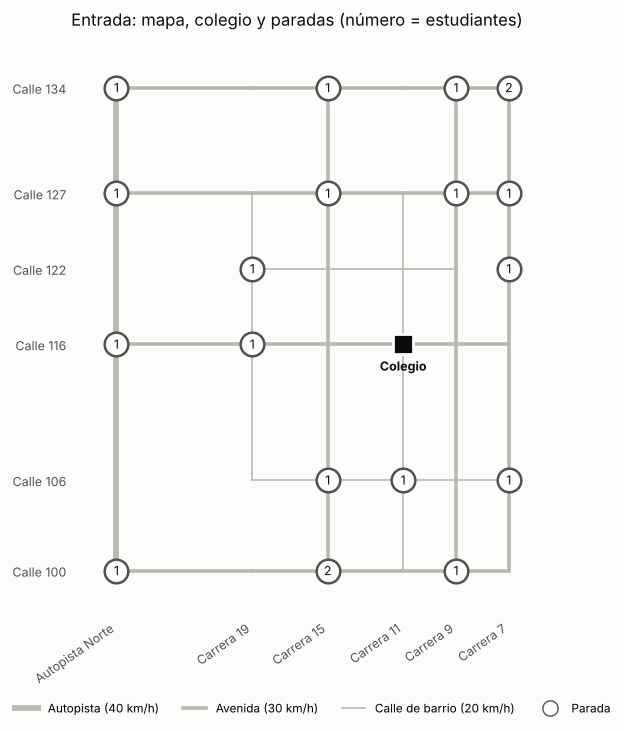

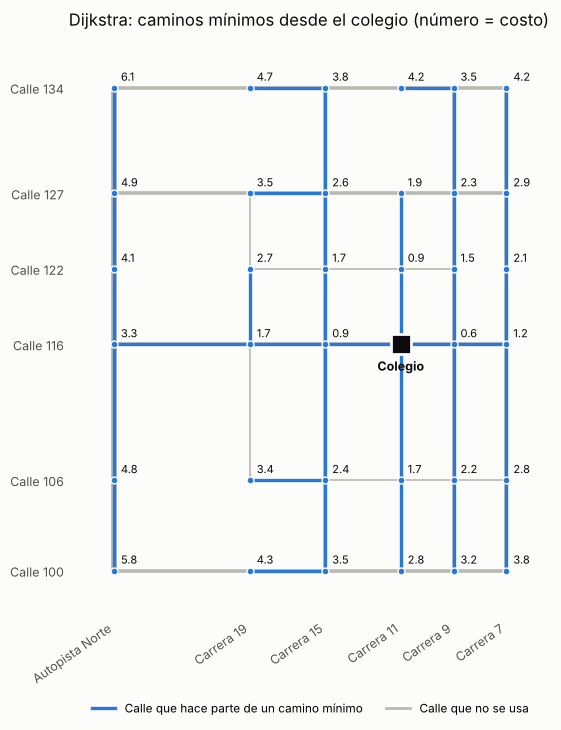

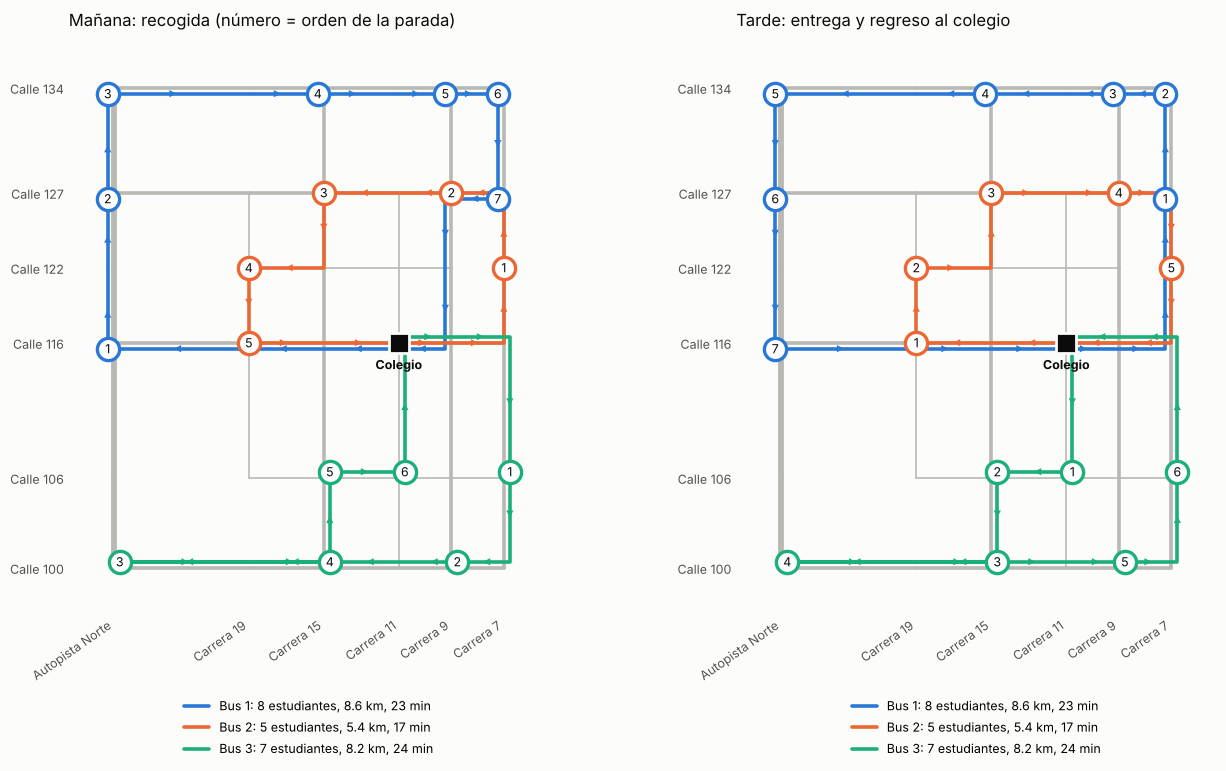

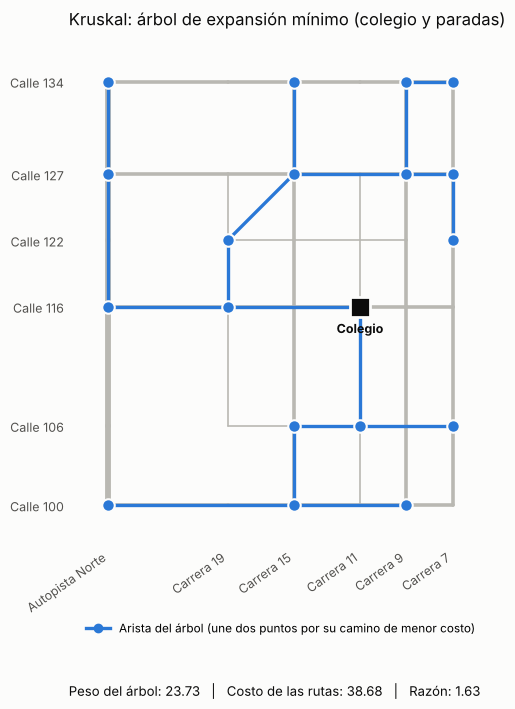

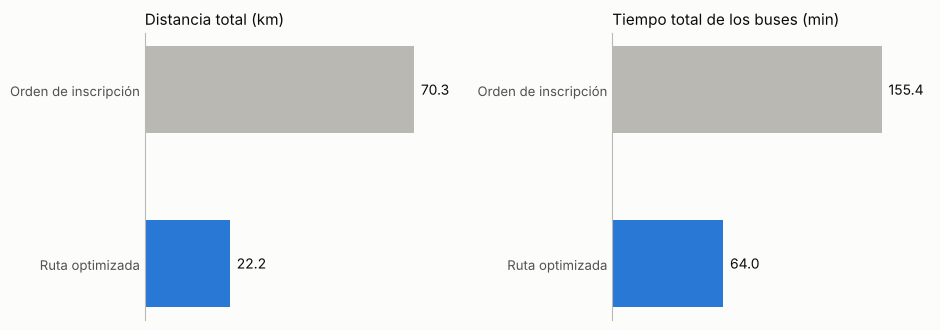

In [6]:
# Figuras del caso principal (son las mismas de la sección 6)
nodos, coords, tramos = construirMapa()
caso_fig = construirCaso(nodos, coords, tramos, COLEGIO, ESTUDIANTES, BUSES)
plan_fig = calcularRutas(caso_fig)
graficarEntrada(caso_fig)
graficarCaminosMinimos(caso_fig)
graficarRutas(caso_fig, plan_fig)
graficarArbolMinimo(caso_fig, plan_fig)
graficarComparacion(caso_fig, plan_fig)


## 10. Plan de pruebas

Las 19 pruebas están en la celda de código que sigue a esta tabla. Para repetirlas solo hay que ejecutar esa celda: los casos ya están en la lista `casos_de_prueba` y no hay que escribir ni cargar nada. Los resultados observados son los de esa ejecución: 19 de 19 pruebas pasaron.

| Caso | Entrada | Resultado esperado | Resultado observado | Evidencia |
|---|---|---|---|---|
| Flujo principal: rutas válidas | 20 estudiantes y 3 buses de 8, 7 y 7 puestos | Cada estudiante en una sola ruta, cupos respetados y recorridos por calles que existen | 20 estudiantes asignados, ocupación 8/8, 5/7 y 7/7, 0 fallas | P1, Recurso 3 |
| Flujo principal: mejora frente al orden de inscripción | El mismo caso | Costo optimizado menor que el costo sin optimizar | 38.68 (22.2 km) contra 120.86 (70.3 km) | P2, Recurso 5 |
| Flujo principal: caminos mínimos | Dijkstra desde el colegio contra relajar todas las calles V - 1 veces | El mismo costo para las 36 esquinas | Diferencia máxima 0 | P3, Recurso 2 |
| Flujo principal: árbol de expansión mínimo | Colegio y 18 paradas | 18 aristas, un solo conjunto, y peso menor o igual al del árbol estrella y al costo de las rutas | 18 aristas, 1 conjunto, peso 23.73 (estrella 59.52, rutas 38.68) | P4, Recurso 4 |
| Flujo principal: ruta de la tarde | Las rutas de los 3 buses | Mismas paradas en orden inverso y los mismos km que en la mañana | Se cumple en los 3 buses | P5, Recurso 3 |
| Flujo principal: vista de padres en la mañana | Estudiante 1003 a las 5:55, 6:10 y 6:20 a. m. | Esperando el bus, luego en el bus, luego en el colegio, con minutos que bajan hasta 0 | Esperando el bus (22 min), en el bus (7 min), en el colegio (0 min) | P6, demo parte 7 |
| Flujo principal: vista de padres en la tarde | Estudiante 1003 a las 2:55, 3:05 y 3:15 p. m. | En el colegio, luego en el bus, luego en casa, con minutos que bajan hasta 0 | En el colegio (13 min), en el bus (3 min), en casa (0 min) | P7, demo parte 7 |
| Caso límite: puestos exactos | 20 estudiantes y buses de 8, 6 y 6 puestos | Rutas válidas con todos los buses llenos | Ocupación 8/8, 6/6 y 6/6, 0 fallas | P8 |
| Caso límite: un solo bus | 8 estudiantes en 7 paradas y un bus de 8 puestos | El mismo costo que la mejor de las 5040 rutas posibles (fuerza bruta) | Programa 22.5449, fuerza bruta 22.5449 | P9 |
| Caso límite: estudiante en la esquina del colegio | 6 estudiantes, una vive en Cl116-Kr11 | Rutas válidas y la estudiante queda con bus | 0 fallas, Paula queda en el bus 2 | P10 |
| Caso límite: un solo estudiante | 1 estudiante y un bus de 8 puestos | Una ruta colegio, parada, colegio que mide dos veces el camino mínimo | 0 fallas, ruta de 4.8 km, ida y vuelta 4.8 km | P11 |
| Caso límite: otra cantidad de buses | Los 20 estudiantes con 2 buses de 10 puestos y con 4 buses de 6 | Rutas válidas en los dos casos | 2 buses: 10/10 y 10/10, 19.9 km. 4 buses: 2/6, 6/6, 6/6 y 6/6, 25.0 km. 0 fallas | P12 |
| Error o dato inválido: más estudiantes que puestos | 20 estudiantes y buses de 5 y 5 puestos | No calcula rutas y avisa | "Hay 20 estudiantes y solo 10 puestos en total" | P13 |
| Error o dato inválido: esquina que no existe | Un estudiante vive en Cl200-Kr7 | No calcula rutas y avisa | "El estudiante 2002 (Pedro) vive en Cl200-Kr7, que no existe en el mapa" | P14 |
| Error o dato inválido: estudiante sin camino | Se cierran las dos calles que llegan a Cl134-Auto | Avisa que el estudiante 1012 queda sin camino al colegio | "El estudiante 1012 (Andres) vive en Cl134-Auto, que no tiene camino al colegio" | P15 |
| Error o dato inválido: datos repetidos o desconocidos | Id repetido, esquina inexistente, consulta de un id desconocido y cierre de una calle que no existe | Se rechazan los cuatro sin cambiar los datos | Los cuatro se rechazan y siguen los 20 estudiantes | P16 |
| Cambio: se cierra una calle que usaban las rutas | Calle 116 entre la Carrera 15 y la Carrera 11 | Rutas válidas sin pasar por la calle cerrada y con costo mayor o igual | 0 fallas, el costo pasa de 38.68 a 40.58 | P17, demo parte 9 |
| Cambio: entra una estudiante y después se retira | Estudiante 1021 en Cl122-Kr11 | Con ella hay 21 estudiantes en rutas válidas; al retirarla vuelven los 20 y el costo inicial | Entra al bus 3 con 0 fallas; al retirarla quedan 20 estudiantes y el costo vuelve a 38.68 | P18, demo parte 8 |
| Estructuras | 7 números en el montón mínimo; insert, update y delete en la tabla hash | El montón entrega en orden; update cambia el valor y delete lo quita | [1, 2, 3, 6, 7, 8, 9]; a = 10; b = None | P19 |


In [7]:
# ===================== PRUEBAS =====================
# Ejecutar esta celda corre las 19 pruebas del plan (sección 10). No hay que escribir ni cargar nada

def verificarPlan(caso, plan):
    # Devuelve la lista de fallas de un plan (vacía si todo está bien)
    fallas = []
    colegio, grafo = caso['colegio'], caso['grafo']
    vistos = []
    for b in range(len(plan['buses'])):
        bus = plan['buses'][b]
        if bus['ocupados'] > bus['cupo']:
            fallas.append('El bus ' + str(b + 1) + ' pasa su cupo')
        for nodo in bus['paradas']:
            for idEst in plan['paradas'][nodo]:
                vistos.append(idEst)
        horario = bus['horarioManana']
        if horario[0]['nodo'] != colegio or horario[len(horario) - 1]['nodo'] != colegio:
            fallas.append('El bus ' + str(b + 1) + ' no sale del colegio o no vuelve a él')
        km = 0
        for p in range(len(horario) - 1):
            u, v = horario[p]['nodo'], horario[p + 1]['nodo']
            if u != v:
                if (u, v) not in grafo.weights:
                    fallas.append('El bus ' + str(b + 1) + ' pasa por una calle que no existe: ' + u + ' - ' + v)
                else:
                    km = km + caso['km'][(u, v)]
        if abs(km - bus['km']) > 0.000001:
            fallas.append('Los km del bus ' + str(b + 1) + ' no coinciden con la suma de sus calles')
    if sorted(vistos) != sorted(caso['ids']):
        fallas.append('Algún estudiante no quedó en exactamente una ruta')
    for idEst in caso['ids']:
        if caso['tabla'].search(idEst)['bus'] is None:
            fallas.append('El estudiante ' + idEst + ' no tiene bus en la tabla hash')
    return fallas


def costosPorRelajacion(grafo, origen):
    # Método de comparación para Dijkstra: relajar todas las calles V - 1 veces
    costo = {}
    for v in grafo.vertexes:
        costo[v] = math.inf
    costo[origen] = 0
    for vuelta in range(len(grafo.vertexes) - 1):
        for relation in grafo.relations:
            if costo[relation[0]] + relation[2] < costo[relation[1]]:
                costo[relation[1]] = costo[relation[0]] + relation[2]
    return costo


def permutaciones(lista):
    # Todas las formas de ordenar la lista (para la fuerza bruta del caso de un bus)
    if len(lista) <= 1:
        return [lista[:]]
    resultado = []
    for i in range(len(lista)):
        resto = lista[:i] + lista[i + 1:]
        for perm in permutaciones(resto):
            resultado.append([lista[i]] + perm)
    return resultado


def casoDePrueba(numero):
    nodos, coords, tramos = construirMapa()
    return construirCaso(nodos, coords, tramos, COLEGIO, casos_de_prueba[numero]['estudiantes'], casos_de_prueba[numero]['buses'])


def ocupacionBuses(plan):
    textos = []
    for bus in plan['buses']:
        textos.append(str(bus['ocupados']) + '/' + str(bus['cupo']))
    return ', '.join(textos)


def reportar(resultados, nombre, esperado, observado, paso):
    marca = 'FALLA'
    if paso:
        marca = 'OK'
    resultados.append(paso)
    print('[' + marca + '] ' + nombre)
    print('       esperado:  ' + esperado)
    print('       observado: ' + observado)


def ejecutar_pruebas():
    resultados = []

    # ---------- Flujo principal ----------
    caso = casoDePrueba(0)
    plan = calcularRutas(caso)
    fallas = verificarPlan(caso, plan)
    reportar(resultados, 'P1  Flujo principal: rutas válidas', 'cada estudiante en una sola ruta, cupos respetados, recorridos por calles que existen',
             str(len(caso['ids'])) + ' estudiantes asignados, ocupación ' + ocupacionBuses(plan) + ', ' + str(len(fallas)) + ' fallas', len(fallas) == 0)

    costoBase, kmBase, minBase = rutaSinOptimizar(caso, plan)
    reportar(resultados, 'P2  Flujo principal: mejora frente al orden de inscripción', 'costo optimizado menor que el costo sin optimizar',
             'optimizado ' + str(round(plan['totalCosto'], 2)) + ' (' + str(round(plan['totalKm'], 1)) + ' km) contra ' + str(round(costoBase, 2)) + ' (' + str(round(kmBase, 1)) + ' km)',
             plan['totalCosto'] < costoBase)

    exacto = costosPorRelajacion(caso['grafo'], caso['colegio'])
    diferencia = 0
    for v in caso['grafo'].vertexes:
        diferencia = max(diferencia, abs(exacto[v] - plan['costo'][(caso['colegio'], v)]))
    reportar(resultados, 'P3  Caminos mínimos: Dijkstra contra relajación de todas las calles', 'el mismo costo para las ' + str(len(caso['grafo'].vertexes)) + ' esquinas',
             'diferencia máxima ' + str(round(diferencia, 9)), diferencia < 0.000001)

    dj = DisjointSets(plan['puntos'])
    for arista in plan['arbol']:
        dj.union(arista[0], arista[1])
    estrella = 0
    for nodo in plan['puntos']:
        estrella = estrella + plan['costo'][(caso['colegio'], nodo)]
    reportar(resultados, 'P4  Árbol de expansión mínimo: Kruskal', str(len(plan['puntos']) - 1) + ' aristas, un solo conjunto, peso <= árbol estrella y <= costo de las rutas',
             str(len(plan['arbol'])) + ' aristas, ' + str(dj.cuentaConjuntos()) + ' conjunto, peso ' + str(round(plan['pesoArbol'], 2)) + ' (estrella ' + str(round(estrella, 2)) + ', rutas ' + str(round(plan['totalCosto'], 2)) + ')',
             len(plan['arbol']) == len(plan['puntos']) - 1 and dj.cuentaConjuntos() == 1 and plan['pesoArbol'] <= estrella and plan['pesoArbol'] <= plan['totalCosto'])

    iguales = True
    for bus in plan['buses']:
        tarde = []
        for punto in bus['horarioTarde']:
            if len(punto['estudiantes']) > 0:
                tarde.append(punto['nodo'])
        tarde.reverse()
        ultimo = bus['horarioTarde'][len(bus['horarioTarde']) - 1]
        if tarde != bus['paradas'] or abs(ultimo['km'] - bus['km']) > 0.000001:
            iguales = False
    reportar(resultados, 'P5  Ruta de la tarde', 'mismas paradas en orden inverso y los mismos km que en la mañana', 'se cumple en los ' + str(len(plan['buses'])) + ' buses: ' + str(iguales), iguales)

    antes = consultarEstudiante(caso, plan, '1003', 'manana', SALIDA_MANANA - 5)
    durante = consultarEstudiante(caso, plan, '1003', 'manana', SALIDA_MANANA + 10)
    despues = consultarEstudiante(caso, plan, '1003', 'manana', SALIDA_MANANA + 20)
    reportar(resultados, 'P6  Vista de padres en la mañana (estudiante 1003)', 'esperando el bus -> en el bus -> en el colegio, con minutos que bajan hasta 0',
             antes['estado'] + ' (' + str(round(antes['minutosParaLlegar'])) + ' min) -> ' + durante['estado'] + ' (' + str(round(durante['minutosParaLlegar'])) + ' min) -> ' + despues['estado'] + ' (' + str(round(despues['minutosParaLlegar'])) + ' min)',
             antes['estado'] == 'esperando el bus' and durante['estado'] == 'en el bus' and despues['estado'] == 'en el colegio'
             and antes['minutosParaLlegar'] > durante['minutosParaLlegar'] > despues['minutosParaLlegar'] == 0)

    antes = consultarEstudiante(caso, plan, '1003', 'tarde', SALIDA_TARDE - 5)
    durante = consultarEstudiante(caso, plan, '1003', 'tarde', SALIDA_TARDE + 5)
    despues = consultarEstudiante(caso, plan, '1003', 'tarde', SALIDA_TARDE + 15)
    reportar(resultados, 'P7  Vista de padres en la tarde (estudiante 1003)', 'en el colegio -> en el bus -> en casa, con minutos que bajan hasta 0',
             antes['estado'] + ' (' + str(round(antes['minutosParaLlegar'])) + ' min) -> ' + durante['estado'] + ' (' + str(round(durante['minutosParaLlegar'])) + ' min) -> ' + despues['estado'] + ' (' + str(round(despues['minutosParaLlegar'])) + ' min)',
             antes['estado'] == 'en el colegio' and durante['estado'] == 'en el bus' and despues['estado'] == 'en casa'
             and antes['minutosParaLlegar'] > durante['minutosParaLlegar'] > despues['minutosParaLlegar'] == 0)

    # ---------- Casos límite ----------
    caso = casoDePrueba(1)
    plan = calcularRutas(caso)
    if len(plan['errores']) == 0:
        fallas = verificarPlan(caso, plan)
        reportar(resultados, 'P8  Límite: puestos exactos (20 estudiantes, 20 puestos)', 'rutas válidas con todos los buses llenos', 'ocupación ' + ocupacionBuses(plan) + ', ' + str(len(fallas)) + ' fallas', len(fallas) == 0)
    else:
        reportar(resultados, 'P8  Límite: puestos exactos (20 estudiantes, 20 puestos)', 'rutas válidas con todos los buses llenos', plan['errores'][0], False)

    caso = casoDePrueba(2)
    plan = calcularRutas(caso)
    ordenes = permutaciones(plan['buses'][0]['paradas'])
    mejor = math.inf
    for orden in ordenes:
        mejor = min(mejor, costoRuta(orden, caso['colegio'], plan['costo']))
    reportar(resultados, 'P9  Límite: un solo bus, comparado con fuerza bruta', 'el mismo costo que la mejor de las ' + str(len(ordenes)) + ' rutas posibles',
             'programa ' + str(round(plan['totalCosto'], 4)) + ', fuerza bruta ' + str(round(mejor, 4)), abs(plan['totalCosto'] - mejor) < 0.000001)

    caso = casoDePrueba(3)
    plan = calcularRutas(caso)
    fallas = verificarPlan(caso, plan)
    paula = consultarEstudiante(caso, plan, '2001', 'manana', SALIDA_MANANA + 120)
    reportar(resultados, 'P10 Límite: estudiante que vive en la esquina del colegio', 'rutas válidas y la estudiante queda con bus',
             str(len(fallas)) + ' fallas, ' + paula['nombre'] + ' en el bus ' + str(paula['bus']) + ', ' + paula['estado'], len(fallas) == 0 and paula['bus'] is not None)

    caso = casoDePrueba(4)
    plan = calcularRutas(caso)
    fallas = verificarPlan(caso, plan)
    idaYVuelta = 2 * plan['kmEntre'][(caso['colegio'], plan['buses'][0]['paradas'][0])]
    reportar(resultados, 'P11 Límite: un solo estudiante', 'una ruta colegio -> parada -> colegio que mide dos veces el camino mínimo',
             str(len(fallas)) + ' fallas, ruta de ' + str(round(plan['totalKm'], 2)) + ' km, ida y vuelta ' + str(round(idaYVuelta, 2)) + ' km',
             len(fallas) == 0 and abs(plan['totalKm'] - idaYVuelta) < 0.000001)

    caso = casoDePrueba(5)
    plan = calcularRutas(caso)
    fallas = verificarPlan(caso, plan)
    caso2 = casoDePrueba(6)
    plan2 = calcularRutas(caso2)
    fallas2 = verificarPlan(caso2, plan2)
    reportar(resultados, 'P12 Otra cantidad de buses: 2 buses de 10 y 4 buses de 6', 'rutas válidas en los dos casos',
             '2 buses: ' + ocupacionBuses(plan) + ', ' + str(round(plan['totalKm'], 1)) + ' km, ' + str(len(fallas)) + ' fallas; 4 buses: ' + ocupacionBuses(plan2) + ', ' + str(round(plan2['totalKm'], 1)) + ' km, ' + str(len(fallas2)) + ' fallas',
             len(fallas) == 0 and len(fallas2) == 0)

    # ---------- Errores y datos inválidos ----------
    caso = casoDePrueba(7)
    plan = calcularRutas(caso)
    reportar(resultados, 'P13 Error: más estudiantes que puestos (20 y 10)', 'no calcula rutas y avisa', '; '.join(plan['errores']), len(plan['errores']) > 0 and 'buses' not in plan)

    caso = casoDePrueba(8)
    plan = calcularRutas(caso)
    reportar(resultados, 'P14 Error: estudiante en una esquina que no existe', 'no calcula rutas y avisa', '; '.join(plan['errores']), len(plan['errores']) > 0 and 'buses' not in plan)

    caso = casoDePrueba(0)
    cerrarCalle(caso, 'Cl134-Auto', 'Cl127-Auto')
    cerrarCalle(caso, 'Cl134-Auto', 'Cl134-Kr19')
    plan = calcularRutas(caso)
    reportar(resultados, 'P15 Error: se cierran las dos calles que llegan a Cl134-Auto', 'avisa que el estudiante 1012 queda sin camino al colegio', '; '.join(plan['errores']), len(plan['errores']) == 1 and '1012' in plan['errores'][0])

    caso = casoDePrueba(0)
    plan = calcularRutas(caso)
    repetido = agregarEstudiante(caso, '1001', 'Otra Ana', 'Cl100-Kr7')
    sinEsquina = agregarEstudiante(caso, '3001', 'Pablo', 'Cl200-Kr7')
    noExiste = consultarEstudiante(caso, plan, '9999', 'manana', SALIDA_MANANA)
    calle = cerrarCalle(caso, 'Cl100-Kr7', 'Cl134-Kr7')
    reportar(resultados, 'P16 Error: id repetido, esquina inexistente, id desconocido y calle inexistente', 'se rechazan los cuatro sin cambiar los datos',
             str(repetido) + '; ' + str(sinEsquina) + '; consulta 9999 = ' + str(noExiste) + '; cerrar calle = ' + str(calle),
             repetido is not None and sinEsquina is not None and noExiste is None and calle == False and len(caso['ids']) == 20)

    # ---------- Cambios ----------
    costoInicial = plan['totalCosto']
    cerrarCalle(caso, 'Cl116-Kr15', 'Cl116-Kr11')
    plan = calcularRutas(caso)
    fallas = verificarPlan(caso, plan)
    reportar(resultados, 'P17 Cambio: se cierra una calle que usaban las rutas', 'rutas válidas sin pasar por la calle cerrada y con costo mayor o igual',
             str(len(fallas)) + ' fallas, costo ' + str(round(costoInicial, 2)) + ' -> ' + str(round(plan['totalCosto'], 2)), len(fallas) == 0 and plan['totalCosto'] >= costoInicial - 0.000001)

    caso = casoDePrueba(0)
    agregado = agregarEstudiante(caso, '1021', 'Emilia', 'Cl122-Kr11')
    plan = calcularRutas(caso)
    fallasCon = verificarPlan(caso, plan)
    busEmilia = consultarEstudiante(caso, plan, '1021', 'manana', SALIDA_MANANA)['bus']
    retirado = retirarEstudiante(caso, '1021')
    plan = calcularRutas(caso)
    fallasSin = verificarPlan(caso, plan)
    reportar(resultados, 'P18 Cambio: entra una estudiante y después se retira', 'con ella hay 21 estudiantes en rutas válidas; al retirarla vuelven los 20 y el costo inicial',
             'entra al bus ' + str(busEmilia) + ' (' + str(len(fallasCon)) + ' fallas); al retirarla quedan ' + str(len(caso['ids'])) + ' estudiantes, costo ' + str(round(plan['totalCosto'], 2)) + ' (' + str(len(fallasSin)) + ' fallas), consulta 1021 = ' + str(consultarEstudiante(caso, plan, '1021', 'manana', SALIDA_MANANA)),
             agregado is None and retirado is None and len(fallasCon) == 0 and len(fallasSin) == 0 and busEmilia is not None and len(caso['ids']) == 20
             and abs(plan['totalCosto'] - costoInicial) < 0.000001 and consultarEstudiante(caso, plan, '1021', 'manana', SALIDA_MANANA) is None)

    # ---------- Estructuras ----------
    pq = PriorityQueue([], False)
    for numero in [7, 3, 9, 1, 8, 2, 6]:
        pq.enqueue(numero)
    salida = []
    while len(pq) > 0:
        salida.append(pq.dequeue())
    tabla = HashTable(7)
    tabla.insert('a', 1)
    tabla.insert('b', 2)
    tabla.update('a', 10)
    tabla.delete('b')
    reportar(resultados, 'P19 Estructuras: montón mínimo y tabla hash', 'el montón entrega en orden; update cambia el valor y delete lo quita',
             'montón ' + str(salida) + '; a = ' + str(tabla.search('a')) + '; b = ' + str(tabla.search('b')),
             salida == [1, 2, 3, 6, 7, 8, 9] and tabla.search('a') == 10 and tabla.search('b') is None)

    print()
    print(resultados.count(True), 'de', len(resultados), 'pruebas pasaron')


ejecutar_pruebas()


[OK] P1  Flujo principal: rutas válidas
       esperado:  cada estudiante en una sola ruta, cupos respetados, recorridos por calles que existen
       observado: 20 estudiantes asignados, ocupación 8/8, 5/7, 7/7, 0 fallas
[OK] P2  Flujo principal: mejora frente al orden de inscripción
       esperado:  costo optimizado menor que el costo sin optimizar
       observado: optimizado 38.68 (22.2 km) contra 120.86 (70.3 km)
[OK] P3  Caminos mínimos: Dijkstra contra relajación de todas las calles
       esperado:  el mismo costo para las 36 esquinas
       observado: diferencia máxima 0
[OK] P4  Árbol de expansión mínimo: Kruskal
       esperado:  18 aristas, un solo conjunto, peso <= árbol estrella y <= costo de las rutas
       observado: 18 aristas, 1 conjunto, peso 23.73 (estrella 59.52, rutas 38.68)
[OK] P5  Ruta de la tarde
       esperado:  mismas paradas en orden inverso y los mismos km que en la mañana
       observado: se cumple en los 3 buses: True
[OK] P6  Vista de padres en la m

## 11. Plan de demo

1. Datos o estado inicial.
   Mapa de la zona entre la Calle 100 y la Calle 134 (36 esquinas y 54 tramos), colegio en la Calle 116 con Carrera 11, 20 estudiantes y 3 buses de 8, 7 y 7 puestos. Se muestra el Recurso 1.
2. Acción del usuario o del sistema.
   El coordinador calcula las rutas. Un padre consulta a la estudiante 1003 a tres horas distintas. Entra la estudiante 1021 y se cierra la Calle 116 entre la Carrera 15 y la Carrera 11.
3. Operación de estructura o algoritmo involucrada.
   Dijkstra con montón mínimo para los caminos, Clarke-Wright con montón máximo y conjuntos disjuntos para repartir, 2-opt para ordenar, Kruskal para la cota, tabla hash para buscar a la estudiante, cola para ubicar el bus y conjuntos disjuntos para validar después del cierre.
4. Resultado visible y relación con el problema de negocio.
   Rutas de la mañana y de la tarde en el mapa (Recurso 3): 22.2 km y 64 min contra 70.3 km y 155 min en orden de inscripción (Problema 1). El padre ve "en el bus, a 2.0 km del colegio, faltan 7 min" (Problema 2). Con la estudiante nueva y la calle cerrada las rutas se recalculan solas: 22.4 km y luego 23.1 km (Problema adicional).
5. Validación o prueba que respalda el resultado.
   Las 19 pruebas de la sección 10: rutas válidas (P1), Dijkstra igual a la relajación completa (P3), la cota de Kruskal (P4), un bus igual a la fuerza bruta (P9) y los avisos de error (P13 a P16).

**Orden de la demo:** se ejecuta `ejecutar_demo()`, que imprime las nueve partes en ese orden, luego la celda de figuras y `ejecutar_pruebas()`. Al final se abre la ventana de escritorio para ver los buses en movimiento y la vista de padres.


# Momento 3 | Pitch y sustentación


## 12. Guion del pitch

1. Consultora, caso y usuario.
2. Problema y evidencia de la necesidad.
3. Solución y propuesta de valor.
4. Operaciones principales y resultado que produce el MVP.
5. Estructuras de datos y algoritmos, con su justificación.
6. Recursos gráficos para explicar las decisiones técnicas.
7. Demo del MVP.
8. Resultados, limitaciones y siguiente paso.


## 13. Ejemplo orientador de pitch: delivery de domicilios con un enjambre de drones

Este ejemplo muestra el nivel esperado de una explicación profesional. No es obligatorio usar este escenario ni todas las estructuras nombradas.

| Lámina | Ejemplo de mensaje |
|---|---|
| Caso | AeroEntrega necesita hacer más predecible el despacho de domicilios urgentes con drones. |
| Problema | La asignación manual no prioriza pedidos críticos, dificulta consultar órdenes y no justifica la conexión entre bases de carga. |
| Propuesta | El MVP registra pedidos, consulta pedidos por código, selecciona el siguiente despacho, propone una ruta mínima y muestra una conexión entre bases. |
| Decisiones DDYA | Tabla hash para pedidos por código; cola de prioridad o montón para el despacho más urgente; caminos mínimos para decidir una ruta; grafo y Kruskal o Prim para conectar bases; conjuntos disjuntos para verificar componentes al usar Kruskal. |
| Demo | Crear pedidos, consultar uno por código, extraer una prioridad, mostrar una ruta mínima y la conexión resultante con una traza, un grafo o una visualización del montón. |
| Valor | Comparar el orden de atención, la ruta y el costo de conexión, y explicar los límites del prototipo. |

**Criterio clave:** cada estructura o algoritmo debe responder a una operación concreta y debe verse en el MVP. Los casos de uso de caminos mínimos y árboles de expansión mínimos son obligatorios.


## 14. Bonus de exploración sectorial

Si el equipo investiga y aplica un algoritmo específico del sector del caso, documenten:

1. Fuente o referencia consultada.
2. Problema del sector que resuelve.
3. Adaptación realizada al MVP.
4. Evidencia de su ejecución.

El bono se reconoce únicamente cuando el algoritmo sea pertinente, esté justificado y se demuestre en el MVP.


## 15. Checklist final

- [ ] El MVP se ejecuta desde una copia limpia siguiendo las instrucciones del equipo.
- [ ] Cada resultado de la demo tiene una prueba o evidencia.
- [ ] Las decisiones de DDYA están conectadas con un caso de uso.
- [ ] El notebook incluye al menos dos recursos gráficos explicados con claridad.
- [ ] El pitch y el notebook usan el mismo caso y vocabulario profesional.
- [ ] El líder reservó una única franja de sustentación en Calendly.
